In [1]:
from pathlib import Path
import importlib
import sys

# Always import the modules shipped beside this notebook, not an older copy.
from pathlib import Path
import sys

def find_project_root(start: Path) -> Path:
    current = start.resolve()

    for candidate in (current, *current.parents):
        if (
            (candidate / "copula_qaoa" / "training.py").exists()
            and (candidate / "instances").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the repository root containing "
        "'copula_qaoa/' and 'instances/'."
    )

PROJECT_ROOT = find_project_root(Path.cwd())

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))



import matplotlib.pyplot as plt
import numpy as np

from copula_qaoa import (
    build_warm_start,
    evaluate_counts,
    evaluate_samples,
    load_knapsack,
    sample_warm_start,
)
import copula_qaoa.training as training_module
importlib.reload(training_module)
from copula_qaoa.training import (
    cvar_from_counts,
    run_sampler_counts,
    train_copula_qaoa,
)

SEED = 1234
np.random.seed(SEED)


## 1. Load and inspect the hard instances
### how they are generated; https://www.sciencedirect.com/science/article/abs/pii/S037722172101016X?via%3Dihub
The generator takes $n, c, g, f, \varepsilon, s$.
Approximately a fraction $f$ of the items belongs to the final small-item group. The remaining items are divided approximately equally among $g-1$ structured groups.

For structured group $j=1, \ldots, g-1$, each item is generated as

$$
v_i=\left\lfloor\left(2^{-j}+\varepsilon\right) c+\xi_i^v\right\rfloor, \quad w_i=\left\lfloor\left(2^{-j}+\varepsilon\right) c+\xi_i^w\right\rfloor,
$$

where $\xi_i^v$ and $\xi_i^w$ are independent random integers from 1 to $s$.
Thus, items within one structured group have nearly equal values and weights. Between consecutive groups, their scale is approximately halved:

$$
\frac{c}{2}, \quad \frac{c}{4}, \quad \frac{c}{8}, \ldots
$$

The remaining items form the final group, where

$$
v_i, w_i \sim \operatorname{Uniform}\{1, \ldots, s\}
$$
### Why can they be hard?
The large items occur at several scales close to fractions of the capacity. Many different combinations of them therefore leave relatively small residual capacities. The final small items can fill these residuals in many different ways.
At the same time, the large structured items have nearly equal value-to-weight ratios. Consequently, many capacity-filling combinations also have very similar objective values. The solver can quickly find good solutions but has difficulty proving which one is optimal because many competing branches remain close to the best solution and cannot be pruned easily.
The authors describe this through inclusionwise maximal solutions: solutions to which no further item can be added. This generator can produce many such solutions, and many of them are near-optimal

### not all generated instances are necessarily hard

Not every instance from this generator is necessarily hard. Instances become particularly difficult when the parameters jointly produce:
- several well-separated scales of large items;
- nearly indistinguishable ratios among those large items;
- enough small items to fill many different residual capacities;
- and many maximal solutions with objective values close to the optimum.
Therefore, the essential source of hardness is not simply correlation between value and weight. It is the combination of multiscale large items, similar efficiencies, and a small-item group that creates many nearly equivalent capacity-filling solutions

Loaded instance: n_100_c_10000000000_g_5_f_0.3_eps_1e-05_s_300.knap
Number of items: 100
Capacity: 10000000000


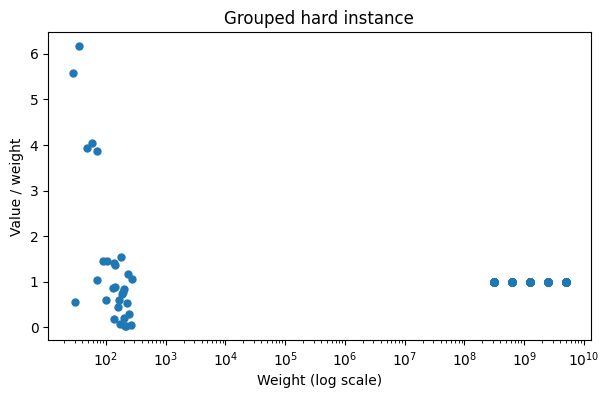

In [2]:
INSTANCE_PATH = (
    PROJECT_ROOT
    / "instances"
    / "n_100_c_10000000000_g_5_f_0.3_eps_1e-05_s_300.knap"
)

if not INSTANCE_PATH.exists():
    raise FileNotFoundError(f"Instance not found: {INSTANCE_PATH}")

instance = load_knapsack(INSTANCE_PATH)

print("Loaded instance:", INSTANCE_PATH.name)
print("Number of items:", len(instance.values))
print("Capacity:", instance.capacity)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(instance.weights, instance.ratios, s=25)
ax.set(xscale="log", xlabel="Weight (log scale)", ylabel="Value / weight", title="Grouped hard instance")
plt.show()


## 2. Weight-aware lazy-greedy warm start

The score is `value / weight - lambda_weight * weight / capacity`. Items are sorted by decreasing score, with the lighter item first for an exact tie. Thus items with similar ratios but very different weights are distinguished. `k` controls how sharply the probabilities change around the greedy cutoff; `lambda_weight` controls the weight penalty.


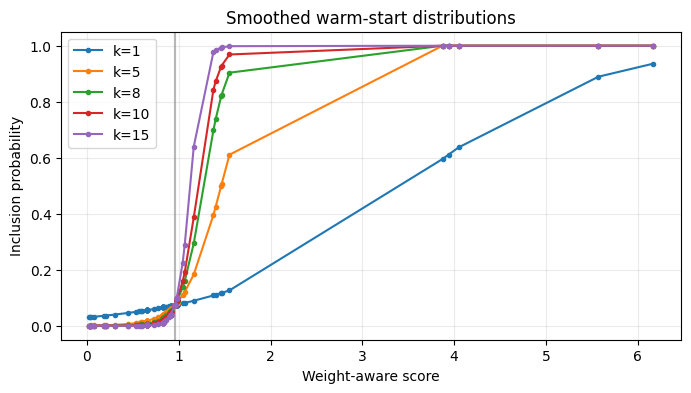

In [3]:
K_VALUES = [1, 5, 8, 10,15]
LAMBDA_WEIGHT = 0.7

warm_starts = {
    k: build_warm_start(
        instance.values, instance.weights, instance.capacity,
        k=k, lambda_weight=LAMBDA_WEIGHT,
    )
    for k in K_VALUES
}

fig, ax = plt.subplots(figsize=(8, 4))
for k, candidate in warm_starts.items():
    ordered = np.argsort(candidate.scores)
    ax.plot(candidate.scores[ordered], candidate.probabilities[ordered], ".-", label=f"k={k}")
    ax.axvline(candidate.cutoff_score, color="grey", alpha=0.15)
ax.set(xlabel="Weight-aware score", ylabel="Inclusion probability", title="Smoothed warm-start distributions")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


Warm-start feasible probability: 0.9991
Best feasible warm-start sample: 9,688,804,363


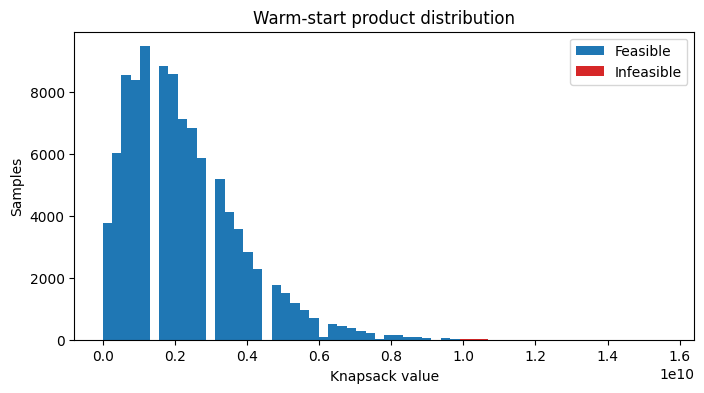

In [4]:
K = 15
N_WARM_SAMPLES = 100_000
warm_start = warm_starts[K]

samples = sample_warm_start(warm_start.probabilities, N_WARM_SAMPLES, seed=SEED)
sample_values, sample_weights, feasible = evaluate_samples(
    samples, instance.values, instance.weights, instance.capacity
)
print(f"Warm-start feasible probability: {feasible.mean():.4f}")
print(f"Best feasible warm-start sample: {sample_values[feasible].max():,}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist([sample_values[feasible], sample_values[~feasible]], bins=60, stacked=True,
        label=["Feasible", "Infeasible"], color=["tab:blue", "tab:red"])
ax.set(xlabel="Knapsack value", ylabel="Samples", title="Warm-start product distribution")
ax.legend()
plt.show()


## 3. Optional Gurobi reference

here we check whether it is important to order the items before feeding to Gurobi


In [5]:
RUN_GUROBI = True
GUROBI_TIME_LIMIT = 1200
GUROBI_OPTIMALITY_GAP = 3e-2
GUROBI_FEASIBILITY_TOLERANCE = 1e-9
GUROBI_INTEGER_TOLERANCE = 1e-9

reference = None
reference_original = None
reference_ordered = None
if RUN_GUROBI:
    from copula_qaoa import solve_with_gurobi
    gurobi_arguments = dict(
        verbose=False, time_limit=GUROBI_TIME_LIMIT,
        optimality_gap=GUROBI_OPTIMALITY_GAP,
        feasibility_tolerance=GUROBI_FEASIBILITY_TOLERANCE,
        integer_tolerance=GUROBI_INTEGER_TOLERANCE,
        #presolve=2, threads=None, method=None, cuts=2, heuristics=0.7,scaling=0,
        node_method=None,  branching=None, solution_limit=None,
    )
    reference_original = solve_with_gurobi(
        instance.values, instance.weights, instance.capacity,
        **gurobi_arguments,
    )
    print('finish')
    gurobi_order = warm_start.order
    reference_ordered = solve_with_gurobi(
        instance.values[gurobi_order], instance.weights[gurobi_order], instance.capacity,
        **gurobi_arguments,
    )
    reference = reference_ordered
    for label, result in [('original order', reference_original), ('warm-start order', reference_ordered)]:
        print(f"{label}: value={result['value']:,}, weight={result['weight']:,}, feasible={result['feasible']}, gap={result['gap']:.6g}, runtime={result['runtime']:.3f}s")
else:
    print("Gurobi was disabled by RUN_GUROBI=False.")


Restricted license - for non-production use only - expires 2027-11-29
finish
original order: value=9,689,707,983.0, weight=9,689,708,183.0, feasible=True, gap=0.0320231, runtime=1200.072s
warm-start order: value=9,689,707,983.0, weight=9,689,708,183.0, feasible=True, gap=0.0320231, runtime=1200.110s


In [7]:
4/1e2

0.04

## 4. Simulator and training settings

`QUICK_MODE=True` performs a real, small end-to-end training run for checking the notebook. Set it to false for the original research-scale depths and shot counts.


In [6]:
import sys
import qiskit
import qiskit_ibm_runtime
import truststore
truststore.inject_into_ssl()  # Use certificates trusted by macOS

print("Python:", sys.executable)
print("Qiskit:", qiskit.__version__)
print("Runtime:", qiskit_ibm_runtime.__version__)

Python: /Users/naeimeh/miniconda3/envs/copula_qaoa_clean/bin/python
Qiskit: 2.1.1
Runtime: 0.43.1


In [ ]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
import sys
import qiskit
import qiskit_ibm_runtime
import truststore
truststore.inject_into_ssl()  # Use certificates trusted by macOS

print("Python:", sys.executable)
print("Qiskit:", qiskit.__version__)
print("Runtime:", qiskit_ibm_runtime.__version__)
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_aer.primitives import EstimatorV2, SamplerV2

QUICK_MODE = False

if QUICK_MODE:
    DEPTHS = (1,)
    TRAINING_SHOTS = 128
    MAXITER = 3
    EVALUATION_SHOTS = 256
else:
    DEPTHS = (1, 2,3,4,5)
    TRAINING_SHOTS = 25_000
    MAXITER = 30_000
    EVALUATION_SHOTS = 100_000

CVaR_ALPHA = 0.1
THETA = -1.0
CONDITIONAL_CVAR = False
service=QiskitRuntimeService(
    token='...',
    #nstance='crn:v1:bluemix:public:quantum-computing:us-east:a/8f99915aec1d4742b2a6a9408b74a1af:5e49230c-df9f-4142-be46-96ac857249bd::',
    #instance='crn:v1:bluemix:public:quantum-computing:eu-de:a/8f99915aec1d4742b2a6a9408b74a1af:3e48594e-1cc7-4c9c-bd9e-3fb0f38de3ac::',
    instance='crn:v1:bluemix:public:quantum-computing:us-east:a/8f99915aec1d4742b2a6a9408b74a1af:e7eca02c-ee10-4326-94a7-d7a3dc9e78cb::',
    channel="ibm_quantum_platform")
backend = service.backend("ibm_marrakesh")

optimization_level = 3
pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=optimization_level,
    seed_transpiler=111,
)

nm = None
coupling_map = backend.configuration().coupling_map
basis_gates = backend.basis_gates

sampler_mps = SamplerV2(
    options={
        "backend_options": {
            "method": "matrix_product_state",
            "matrix_product_state_max_bond_dimension": 100,
            "noise_model": nm,
            "coupling_map": coupling_map,
        }
    }
)

qiskit_runtime_service._discover_account:WARNING:2026-09-18 18:32:23,652: Loading account with the given token. A saved account will not be used.


Python: /Users/naeimeh/miniconda3/envs/copula_qaoa_clean/bin/python
Qiskit: 2.1.1
Runtime: 0.43.1


## 5. Train Copula-QAOA with a CVaR objective

At every optimizer evaluation, the circuit is sampled, infeasible outcomes are assigned no reward, and the mean of the best `alpha` probability mass is maximized. Angles from one depth are interpolated to initialize the next depth.


In [9]:
# Apply the weight-aware warm-start ordering
order = warm_start.order

ordered_values = instance.values[order]
ordered_weights = instance.weights[order]
ordered_probabilities = warm_start.probabilities[order]

print("Depths:", DEPTHS)
print("Training shots:", TRAINING_SHOTS)
print("Maximum iterations:", MAXITER)

Depths: (1, 2, 3, 4, 5)
Training shots: 25000
Maximum iterations: 30000


In [12]:
from datetime import datetime

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
RESULTS_DIR = PROJECT_ROOT / "results" / f"{instance.name}_{RUN_ID}"
COMPILATION_METADATA = {
    "backend": backend.name,
    "optimization_level": optimization_level,
    "seed_transpiler": 111,
    "basis_gates": list(backend.basis_gates),
}
print("Experiment artifacts:", RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

import hashlib
import json
np.savez_compressed(
    RESULTS_DIR / "warm_start.npz",
    probabilities=ordered_probabilities, scores=warm_start.scores[order],
    order=order, greedy_solution=warm_start.greedy_solution[order],
)
experiment_configuration = {
    "instance_path": str(INSTANCE_PATH),
    "instance_sha256": hashlib.sha256(INSTANCE_PATH.read_bytes()).hexdigest(),
    "k": K, "lambda_weight": LAMBDA_WEIGHT, "theta": THETA,
    "cvar_alpha": CVaR_ALPHA, "depths": list(DEPTHS),
    "training_shots": TRAINING_SHOTS, "evaluation_shots": EVALUATION_SHOTS,
    "maxiter": MAXITER, "compilation": COMPILATION_METADATA,
}
(RESULTS_DIR / "experiment_configuration.json").write_text(
    json.dumps(experiment_configuration, indent=2)
)

training_results = train_copula_qaoa(
    ordered_values,
    ordered_weights,
    instance.capacity,
    ordered_probabilities,
    sampler_mps,
    basis_gates=None,  # Training is compiled for the Aer MPS simulator.
    depths=DEPTHS,
    shots=TRAINING_SHOTS,
    alpha=CVaR_ALPHA,
    theta=THETA,
    initial_beta=1.78,
    initial_gamma=1.25,
    maxiter=MAXITER,
    tolerance=1e-2,
    artifact_directory=RESULTS_DIR,
    analysis_pass_manager=pm,
    compilation_metadata=COMPILATION_METADATA,
)

for depth, result in training_results.items():
    print(
        f"p={depth}: CVaR={result.objective:,.2f}, "
        f"feasible={result.feasible_probability:.4f}, "
        f"best={result.best_feasible_value}, evaluations={result.evaluations}, "
        f"success={result.success}"
    )

print("\nCircuit resources before and after compilation")
print(f'{"p":>2} {"representation":>20} {"depth":>8} {"1q depth":>10} {"2q depth":>10} {"1q gates":>10} {"2q gates":>10}')
for depth, result in training_results.items():
    for metrics in result.circuit_report["metrics"]:
        print(
            f'{depth:2d} {metrics["representation"]:>20} '
            f'{metrics["total_depth"]:8d} {metrics["one_qubit_depth"]:10d} '
            f'{metrics["two_qubit_depth"]:10d} {metrics["one_qubit_gates"]:10d} '
            f'{metrics["two_qubit_gates"]:10d}'
        )


Experiment artifacts: /Users/naeimeh/Downloads/Copula_QAOA/results/n_100_c_10000000000_g_5_f_0.3_eps_1e-05_s_300_20260919_204205

Training Copula-QAOA at p=1
CVaR=7,101,753,384.3994, feasible=0.9917, best=9688604247
CVaR=3,692,597,186.0081, feasible=0.9999, best=9688103047
CVaR=7,857,313,477.5110, feasible=0.9818, best=9688704102
CVaR=7,475,178,816.5278, feasible=0.9888, best=9688804178
CVaR=7,855,440,083.4002, feasible=0.9816, best=9688804444
Optimized beta: [1.78]
Optimized gamma: [2.25]
Final CVaR: 7882935278.225002

Training Copula-QAOA at p=2
CVaR=9,156,095,461.5167, feasible=0.8460, best=9688804578
CVaR=5,842,943,168.8509, feasible=0.9978, best=9688303697
CVaR=6,399,852,286.1778, feasible=0.9912, best=9688203641
CVaR=9,276,035,141.1403, feasible=0.7743, best=9688905091
CVaR=9,328,571,665.9999, feasible=0.7596, best=9688904792
CVaR=9,249,959,768.0323, feasible=0.8081, best=9689004428
CVaR=9,228,060,734.5015, feasible=0.8246, best=9688904798
CVaR=9,321,332,958.5671, feasible=0.7515

## 6. Final evaluation at every trained depth

As in the original notebook, the optimized circuits are sampled again with `EVALUATION_SHOTS`. These independent final counts are used for AR, best-value, feasibility, and post-processing comparisons.


p=1: AR=0.717121, AR valid shots=20000, best=9688703759, valid ratio=0.9815
p=2: AR=0.915191, AR valid shots=20000, best=9689005392, valid ratio=0.7565
p=3: AR=0.951960, AR valid shots=20000, best=9689205282, valid ratio=0.5787
p=4: AR=0.945973, AR valid shots=20000, best=9689505684, valid ratio=0.4832
p=5: AR=0.961782, AR valid shots=20000, best=9689605918, valid ratio=0.5197
Saved final evaluation counts and summaries in /Users/naeimeh/Downloads/Copula_QAOA/results/n_100_c_10000000000_g_5_f_0.3_eps_1e-05_s_300_20260919_204205


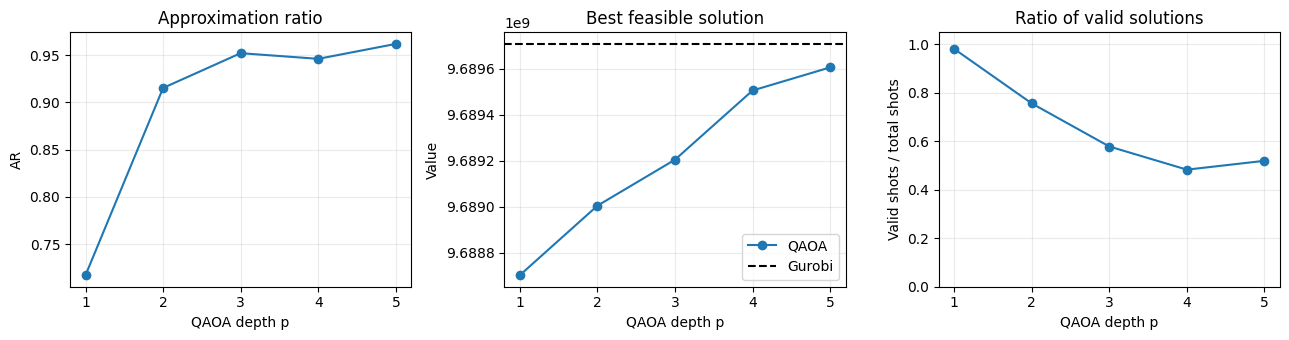

In [13]:
from copula_qaoa.training import approximation_ratio, extract_counts

AR_MAX_SAMPLES = 20_000

evaluation_circuits = []
evaluation_depths = sorted(training_results)
for depth in evaluation_depths:
    measured = training_results[depth].circuit.copy()
    measured.measure_active()
    evaluation_circuits.append(pm.run(measured))

evaluation_job = sampler_mps.run(
    evaluation_circuits,
    shots=EVALUATION_SHOTS,
)
evaluation_result = evaluation_job.result()

evaluation = {}
approximation_ratio_axis = []
best_solution_axis = []
valid_ratio_axis = []

for depth, pub_result in zip(evaluation_depths, evaluation_result):
    counts = extract_counts(pub_result)
    summary = evaluate_counts(
        counts, ordered_values, ordered_weights, instance.capacity
    )
    cvar, _, _ = cvar_from_counts(
        counts,
        ordered_values,
        ordered_weights,
        instance.capacity,
        alpha=CVaR_ALPHA,
        conditional_on_feasible=CONDITIONAL_CVAR,
    )
    evaluation[depth] = {"counts": counts, "summary": summary, "cvar": cvar}

    if reference is None:
        ar, valid_shots_used = np.nan, 0
    else:
        ar, valid_shots_used = approximation_ratio(
            summary.feasible_by_value,
            reference["value"],
            max_samples=AR_MAX_SAMPLES,
        )
    approximation_ratio_axis.append(ar)
    best_solution_axis.append(summary.best_feasible_value)
    valid_ratio_axis.append(summary.feasible_probability)
    print(
        f"p={depth}: AR={ar:.6f}, AR valid shots={valid_shots_used}, "
        f"best={summary.best_feasible_value}, "
        f"valid ratio={summary.feasible_probability:.4f}"
    )

from copula_qaoa.artifacts import save_evaluation_results
save_evaluation_results(RESULTS_DIR, evaluation, reference=reference)
print(f"Saved final evaluation counts and summaries in {RESULTS_DIR / 'simulator'}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(evaluation_depths, approximation_ratio_axis, "o-")
axes[0].set(title="Approximation ratio", xlabel="QAOA depth p", ylabel="AR")
axes[1].plot(evaluation_depths, best_solution_axis, "o-", label="QAOA")
if reference is not None:
    axes[1].axhline(reference["value"], color="black", linestyle="--", label="Gurobi")
axes[1].set(title="Best feasible solution", xlabel="QAOA depth p", ylabel="Value")
axes[1].legend()
axes[2].plot(evaluation_depths, valid_ratio_axis, "o-")
axes[2].set(
    title="Ratio of valid solutions", xlabel="QAOA depth p",
    ylabel="Valid shots / total shots", ylim=(0, 1.05)
)
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
# import importlib
# import copula_qaoa.postprocessing as postprocessing_module

# importlib.reload(postprocessing_module)
# print("Post-processing functions reloaded.")

Updated greedy repair functions loaded.


## 7. Feasibility repair and greedy completion

The following comparison distinguishes the original sampled solutions from two levels of classical post-processing.

**Before repair** means that the random, warm-start, or QAOA samples are evaluated exactly as generated. No bits are changed.

**Repair only** makes an infeasible bitstring feasible. Selected items are ordered from lowest to highest value-to-weight ratio, and one selected item is removed at a time until the total weight satisfies the capacity. For an exact ratio tie, the heavier selected item is removed first. The procedure stops immediately when feasibility is reached; it does not add any item afterward. A sample that is already feasible is left unchanged.

**Repair + greedy completion** first performs the same feasibility repair. It then considers unselected items from highest to lowest value-to-weight ratio and adds one item at a time whenever it fits within the remaining capacity. For an exact ratio tie, the lighter item is considered first.

Here, *greedy* means that each decision follows the current ratio ranking without exploring all possible exchanges or combinations. Therefore, repair plus completion can improve the sampled value, but it is a classical heuristic and does not guarantee the globally optimal knapsack solution. Results before repair, after repair only, and after repair plus completion are reported separately so that the contribution of QAOA is not confused with the contribution of classical post-processing.

Saved plotted distributions to /Users/naeimeh/Downloads/Copula_QAOA/results/n_100_c_10000000000_g_5_f_0.3_eps_1e-05_s_300_20260919_204205/postprocessing_comparison.json


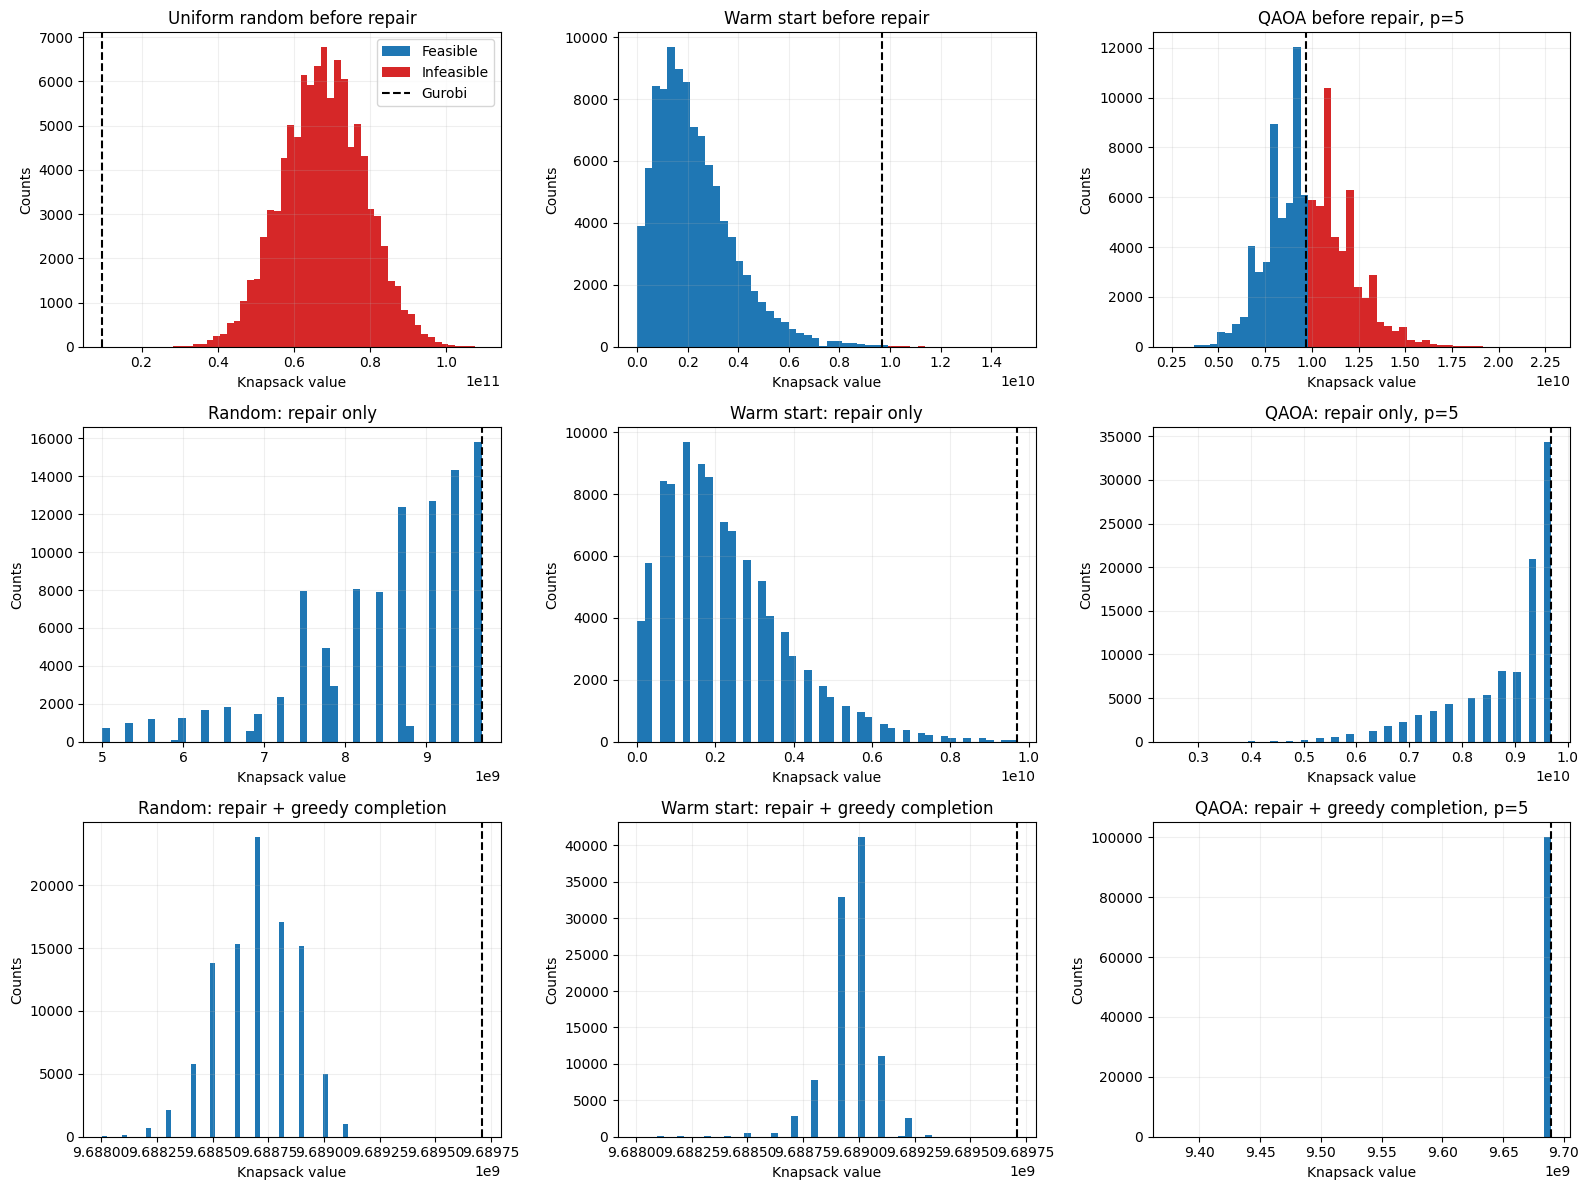

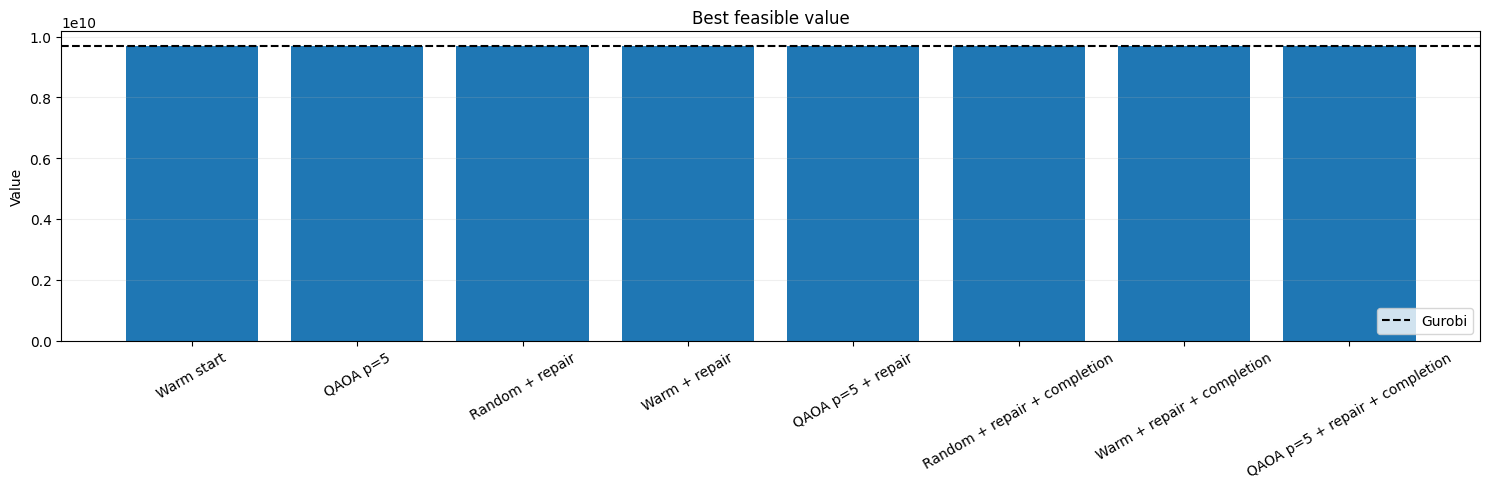


Feasible ratios
Random before repair:                 0.0000
Random after repair only:             1.0000
Random after repair + completion:     1.0000
Warm start before repair:             0.9990
Warm start after repair only:         1.0000
Warm start after repair + completion: 1.0000
QAOA before repair:                   p=1: 0.9815 | p=2: 0.7565 | p=3: 0.5787 | p=4: 0.4832 | p=5: 0.5197
QAOA after repair only:               p=1: 1.0000 | p=2: 1.0000 | p=3: 1.0000 | p=4: 1.0000 | p=5: 1.0000
QAOA after repair + completion:       p=1: 1.0000 | p=2: 1.0000 | p=3: 1.0000 | p=4: 1.0000 | p=5: 1.0000

Best feasible values
Random before repair:                 None
Random after repair only:             9688904819
Random after repair + completion:     9689107590
Warm start before repair:             9688504240
Warm start after repair only:         9688504240
Warm start after repair + completion: 9689507624
QAOA before repair:                   p=1: 9688703759 | p=2: 9689005392 | p=3: 968920

In [15]:
from collections import defaultdict
import importlib

import copula_qaoa.postprocessing as postprocessing_module
from copula_qaoa.artifacts import (
    save_postprocessing_comparison,
    summarize_sample_values,
)

importlib.reload(postprocessing_module)

repair_only_counts = postprocessing_module.repair_counts
repair_only_samples = postprocessing_module.repair_samples
repair_and_complete_counts = postprocessing_module.repair_and_complete_counts
repair_and_complete_samples = postprocessing_module.repair_and_complete_samples

final_depth = max(evaluation)
qaoa_counts = evaluation[final_depth]["counts"]
comparison_shots = sum(qaoa_counts.values())

# ------------------------------------------------------------------
# Uniform random sampling: each bit independently has probability 1/2.
# ------------------------------------------------------------------
random_counts = defaultdict(int)

for _ in range(comparison_shots):
    bitstring = "".join(
        str(x) for x in np.random.randint(2, size=len(ordered_values))
    )
    random_counts[bitstring] += 1

random_summary = evaluate_counts(
    random_counts,
    ordered_values,
    ordered_weights,
    instance.capacity,
    reverse_bitstrings=False,
)

# ------------------------------------------------------------------
# Sample the warm-start distribution supplied to QAOA.
# ------------------------------------------------------------------
rng = np.random.default_rng(SEED)

warm_samples_ordered = rng.random(
    (comparison_shots, len(ordered_probabilities))
) < ordered_probabilities

warm_values_ordered, _, warm_feasible_ordered = evaluate_samples(
    warm_samples_ordered,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

repair_only_warm_samples = repair_only_samples(
    warm_samples_ordered,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

repair_only_warm_values, _, repair_only_warm_feasible = evaluate_samples(
    repair_only_warm_samples,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

completed_warm_samples = repair_and_complete_samples(
    warm_samples_ordered,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

completed_warm_values, _, completed_warm_feasible = evaluate_samples(
    completed_warm_samples,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

# ------------------------------------------------------------------
# Postprocess random samples.
# These functions expect Qiskit-order bitstrings.
# ------------------------------------------------------------------
random_counts_qiskit = {
    bitstring[::-1]: count
    for bitstring, count in random_counts.items()
}

repair_only_random_counts = repair_only_counts(
    random_counts_qiskit,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

completed_random_counts = repair_and_complete_counts(
    random_counts_qiskit,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

repair_only_random_summary = evaluate_counts(
    repair_only_random_counts,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

completed_random_summary = evaluate_counts(
    completed_random_counts,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

# ------------------------------------------------------------------
# Postprocess the existing QAOA counts for EVERY evaluated depth.
# No QAOA training or sampling is repeated.
# Both postprocessing methods start from the original counts.
# ------------------------------------------------------------------
qaoa_postprocessing_by_depth = {}

for depth in sorted(evaluation):
    counts_before = evaluation[depth]["counts"]

    counts_repair = repair_only_counts(
        counts_before,
        ordered_values,
        ordered_weights,
        instance.capacity,
    )

    counts_complete = repair_and_complete_counts(
        counts_before,
        ordered_values,
        ordered_weights,
        instance.capacity,
    )

    stage_counts = {
        "before": counts_before,
        "repair": counts_repair,
        "complete": counts_complete,
    }

    qaoa_postprocessing_by_depth[depth] = {}

    for stage, counts in stage_counts.items():
        if sum(counts.values()) != sum(counts_before.values()):
            raise ValueError(
                f"Postprocessing changed the shot count for p={depth}, "
                f"stage={stage}."
            )

        summary = evaluate_counts(
            counts,
            ordered_values,
            ordered_weights,
            instance.capacity,
        )

        qaoa_postprocessing_by_depth[depth][stage] = {
            "counts": counts,
            "summary": summary,
        }

# Keep final-depth variables for the existing plots and downstream cells.
final_qaoa = qaoa_postprocessing_by_depth[final_depth]

qaoa_summary = final_qaoa["before"]["summary"]

repair_only_qaoa_counts = final_qaoa["repair"]["counts"]
repair_only_qaoa_summary = final_qaoa["repair"]["summary"]

completed_qaoa_counts = final_qaoa["complete"]["counts"]
completed_qaoa_summary = final_qaoa["complete"]["summary"]

# ------------------------------------------------------------------
# Save the distributions used in the final-depth comparison plot.
# ------------------------------------------------------------------
comparison_distributions = {
    "random_before": random_summary,
    "warm_before": summarize_sample_values(
        warm_values_ordered, warm_feasible_ordered
    ),
    "qaoa_before": qaoa_summary,

    "random_repair": repair_only_random_summary,
    "warm_repair": summarize_sample_values(
        repair_only_warm_values, repair_only_warm_feasible
    ),
    "qaoa_repair": repair_only_qaoa_summary,

    "random_complete": completed_random_summary,
    "warm_complete": summarize_sample_values(
        completed_warm_values, completed_warm_feasible
    ),
    "qaoa_complete": completed_qaoa_summary,
}

comparison_file = save_postprocessing_comparison(
    RESULTS_DIR / "postprocessing_comparison.json",
    comparison_distributions,
    final_depth=final_depth,
    reference_value=None if reference is None else reference["value"],
)

print(f"Saved plotted distributions to {comparison_file}")

# ------------------------------------------------------------------
# Plot distributions: random, warm start, and final-depth QAOA.
# ------------------------------------------------------------------
def plot_count_distribution(ax, summary, title):
    ax.hist(
        [
            list(summary.feasible_by_value),
            list(summary.infeasible_by_value),
        ],
        weights=[
            list(summary.feasible_by_value.values()),
            list(summary.infeasible_by_value.values()),
        ],
        bins=50,
        stacked=True,
        density=False,
        color=["tab:blue", "tab:red"],
        label=["Feasible", "Infeasible"],
    )
    ax.set_title(title)


fig, axes = plt.subplots(3, 3, figsize=(16, 12))

plot_count_distribution(
    axes[0, 0], random_summary, "Uniform random before repair"
)
axes[0, 1].hist(
    [
        warm_values_ordered[warm_feasible_ordered],
        warm_values_ordered[~warm_feasible_ordered],
    ],
    bins=50,
    stacked=True,
    density=False,
    color=["tab:blue", "tab:red"],
    label=["Feasible", "Infeasible"],
)
axes[0, 1].set_title("Warm start before repair")

plot_count_distribution(
    axes[0, 2],
    qaoa_summary,
    f"QAOA before repair, p={final_depth}",
)

plot_count_distribution(
    axes[1, 0],
    repair_only_random_summary,
    "Random: repair only",
)
axes[1, 1].hist(
    [
        repair_only_warm_values[repair_only_warm_feasible],
        repair_only_warm_values[~repair_only_warm_feasible],
    ],
    bins=50,
    stacked=True,
    density=False,
    color=["tab:blue", "tab:red"],
    label=["Feasible", "Infeasible"],
)
axes[1, 1].set_title("Warm start: repair only")

plot_count_distribution(
    axes[1, 2],
    repair_only_qaoa_summary,
    f"QAOA: repair only, p={final_depth}",
)

plot_count_distribution(
    axes[2, 0],
    completed_random_summary,
    "Random: repair + greedy completion",
)
axes[2, 1].hist(
    [
        completed_warm_values[completed_warm_feasible],
        completed_warm_values[~completed_warm_feasible],
    ],
    bins=50,
    stacked=True,
    density=False,
    color=["tab:blue", "tab:red"],
    label=["Feasible", "Infeasible"],
)
axes[2, 1].set_title("Warm start: repair + greedy completion")

plot_count_distribution(
    axes[2, 2],
    completed_qaoa_summary,
    f"QAOA: repair + greedy completion, p={final_depth}",
)

for ax in axes.flat:
    if reference is not None:
        ax.axvline(
            reference["value"],
            color="black",
            linestyle="--",
            label="Gurobi",
        )
    ax.set_xlabel("Knapsack value")
    ax.set_ylabel("Counts")
    ax.grid(alpha=0.2)

axes[0, 0].legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# Best feasible values.
# ------------------------------------------------------------------
warm_best_before = (
    np.max(warm_values_ordered[warm_feasible_ordered]).item()
    if np.any(warm_feasible_ordered) else None
)
warm_best_repair = (
    np.max(repair_only_warm_values[repair_only_warm_feasible]).item()
    if np.any(repair_only_warm_feasible) else None
)
warm_best_completed = (
    np.max(completed_warm_values[completed_warm_feasible]).item()
    if np.any(completed_warm_feasible) else None
)

labels = [
    "Random", "Warm start", f"QAOA p={final_depth}",
    "Random + repair", "Warm + repair", f"QAOA p={final_depth} + repair",
    "Random + repair + completion",
    "Warm + repair + completion",
    f"QAOA p={final_depth} + repair + completion",
]

best_values_comparison = [
    random_summary.best_feasible_value,
    warm_best_before,
    qaoa_summary.best_feasible_value,
    repair_only_random_summary.best_feasible_value,
    warm_best_repair,
    repair_only_qaoa_summary.best_feasible_value,
    completed_random_summary.best_feasible_value,
    warm_best_completed,
    completed_qaoa_summary.best_feasible_value,
]

fig, ax = plt.subplots(figsize=(15, 5))
ax.bar(
    labels,
    [np.nan if value is None else value for value in best_values_comparison],
)
ax.tick_params(axis="x", rotation=30)
ax.set(title="Best feasible value", ylabel="Value")

if reference is not None:
    ax.axhline(
        reference["value"],
        color="black",
        linestyle="--",
        label="Gurobi",
    )
    ax.legend()

ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# Format all QAOA depths on the same output line.
# ------------------------------------------------------------------
def format_qaoa_depths(stage, field):
    entries = []

    for depth in sorted(qaoa_postprocessing_by_depth):
        summary = qaoa_postprocessing_by_depth[depth][stage]["summary"]
        value = getattr(summary, field)

        if field == "feasible_probability":
            value_text = f"{value:.4f}"
        else:
            value_text = str(value)

        entries.append(f"p={depth}: {value_text}")

    return " | ".join(entries)


print("\nFeasible ratios")
print(
    f"Random before repair:                 "
    f"{random_summary.feasible_probability:.4f}"
)
print(
    f"Random after repair only:             "
    f"{repair_only_random_summary.feasible_probability:.4f}"
)
print(
    f"Random after repair + completion:     "
    f"{completed_random_summary.feasible_probability:.4f}"
)
print(f"Warm start before repair:             {warm_feasible_ordered.mean():.4f}")
print(f"Warm start after repair only:         {repair_only_warm_feasible.mean():.4f}")
print(f"Warm start after repair + completion: {completed_warm_feasible.mean():.4f}")

print(
    "QAOA before repair:                   "
    + format_qaoa_depths("before", "feasible_probability")
)
print(
    "QAOA after repair only:               "
    + format_qaoa_depths("repair", "feasible_probability")
)
print(
    "QAOA after repair + completion:       "
    + format_qaoa_depths("complete", "feasible_probability")
)

print("\nBest feasible values")
print(f"Random before repair:                 {random_summary.best_feasible_value}")
print(f"Random after repair only:             {repair_only_random_summary.best_feasible_value}")
print(f"Random after repair + completion:     {completed_random_summary.best_feasible_value}")
print(f"Warm start before repair:             {warm_best_before}")
print(f"Warm start after repair only:         {warm_best_repair}")
print(f"Warm start after repair + completion: {warm_best_completed}")

print(
    "QAOA before repair:                   "
    + format_qaoa_depths("before", "best_feasible_value")
)
print(
    "QAOA after repair only:               "
    + format_qaoa_depths("repair", "best_feasible_value")
)
print(
    "QAOA after repair + completion:       "
    + format_qaoa_depths("complete", "best_feasible_value")
)

Saved all plotted distributions to /Users/naeimeh/Downloads/Copula_QAOA/results/n_100_c_10000000000_g_5_f_0.3_eps_1e-05_s_300_20260919_204205/postprocessing_comparison.json


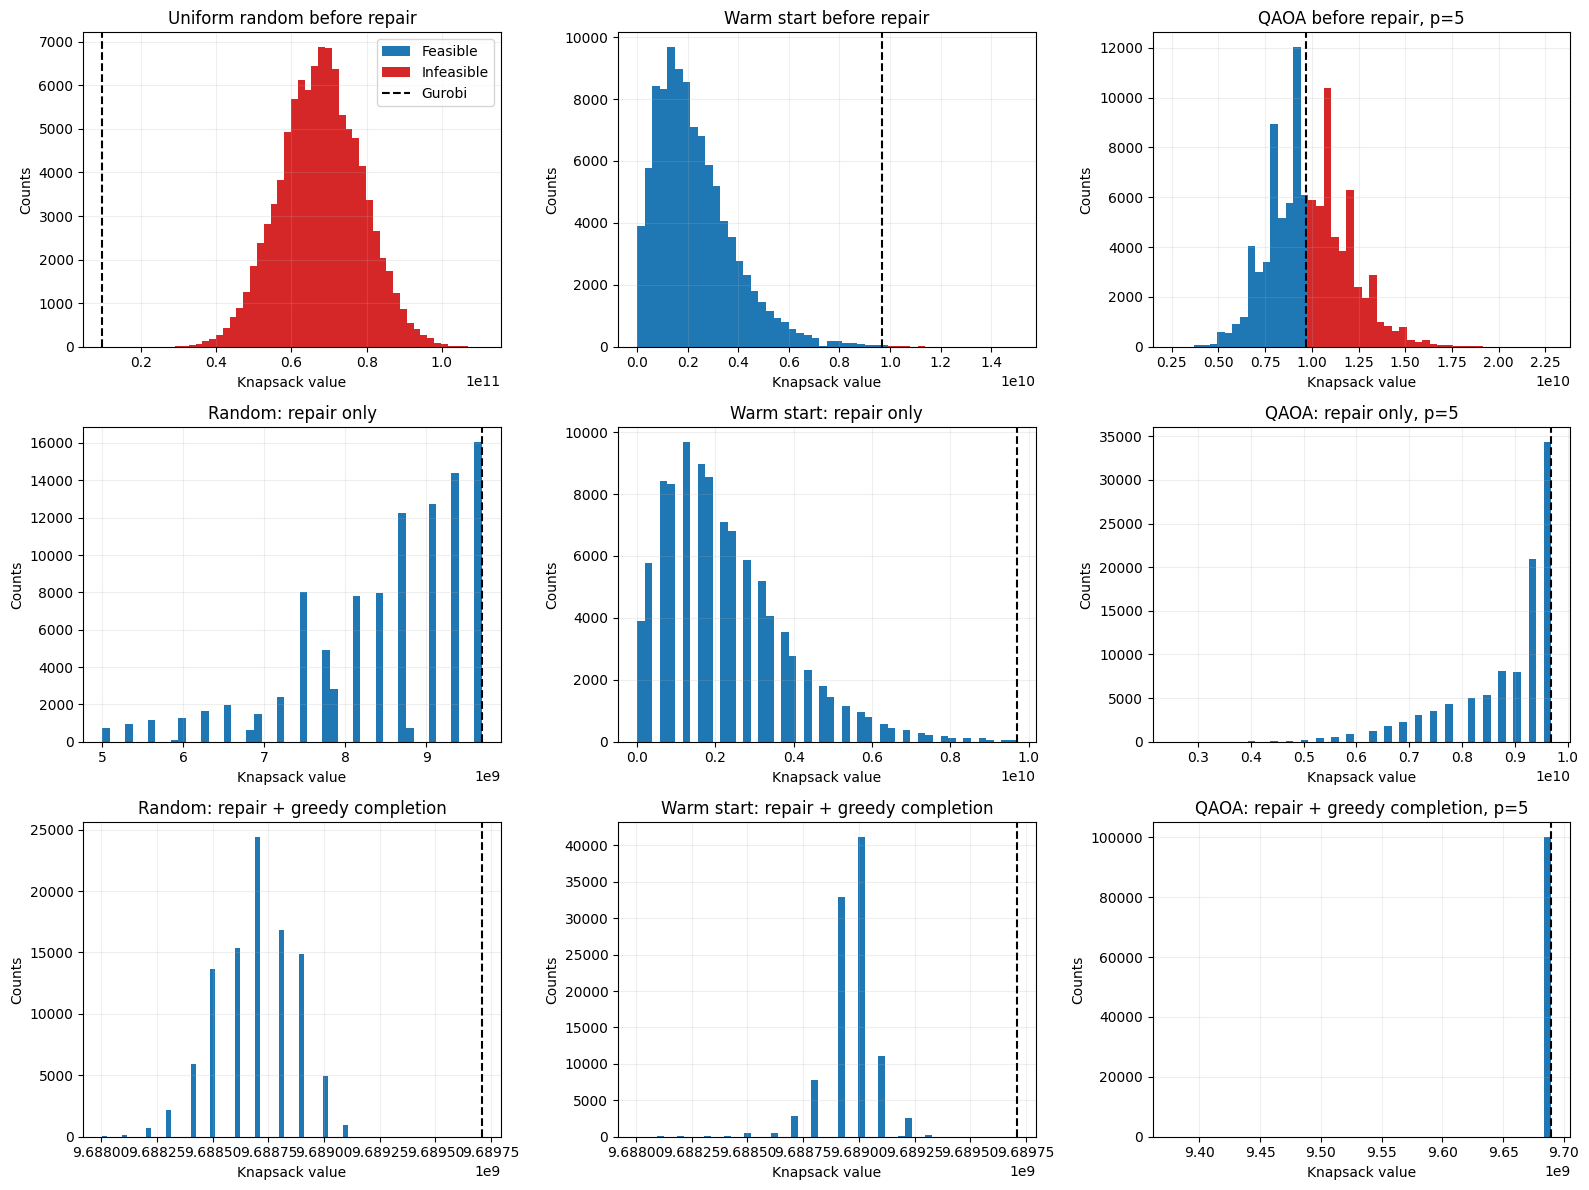

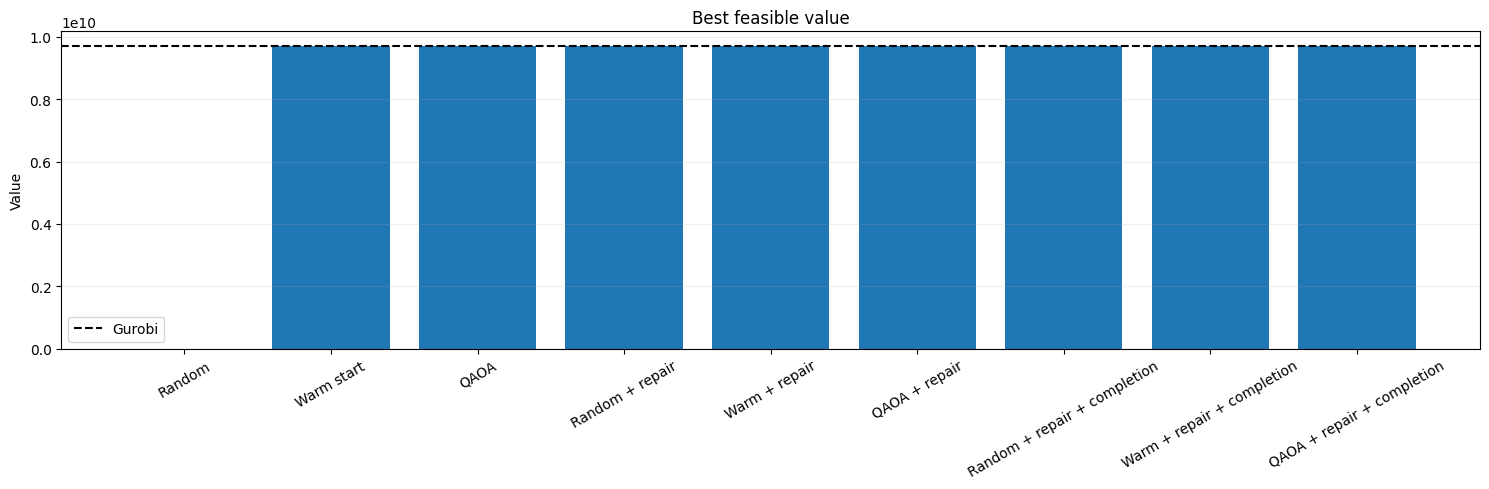

Random feasible ratio before repair: 0.0000
Random feasible ratio after repair only: 1.0000
Random feasible ratio after repair + completion: 1.0000
Warm-start feasible ratio before:    0.9990
Warm-start feasible ratio after repair only: 1.0000
Warm-start feasible ratio after repair + completion: 1.0000
QAOA feasible ratio before repair:   0.5197
QAOA feasible ratio after repair only: 1.0000
QAOA feasible ratio after repair + completion: 1.0000

Best feasible values
Random before repair:                 None
Random after repair only:             9688905287
Random after repair + completion:     9689107590
Warm start before repair:             9688504240
Warm start after repair only:         9688504240
Warm start after repair + completion: 9689507624
QAOA before repair:                   9689605918
QAOA after repair only:               9689605918
QAOA after repair + completion:       9689707930


In [14]:
from collections import defaultdict

import importlib
import copula_qaoa.postprocessing as postprocessing_module
importlib.reload(postprocessing_module)
repair_only_counts = postprocessing_module.repair_counts
repair_only_samples = postprocessing_module.repair_samples
repair_and_complete_counts = postprocessing_module.repair_and_complete_counts
repair_and_complete_samples = postprocessing_module.repair_and_complete_samples

final_depth = max(evaluation)
qaoa_counts = evaluation[final_depth]["counts"]
qaoa_summary = evaluation[final_depth]["summary"]
comparison_shots = sum(qaoa_counts.values())

# Original uniform random sampler: every bit is independently 0 or 1 with
# equal probability. The bitstrings are already in ordered-item convention.
random_counts = defaultdict(int)
for _ in range(comparison_shots):
    bitstring = "".join(
        str(x) for x in np.random.randint(2, size=len(ordered_values))
    )
    random_counts[bitstring] += 1

# random_counts are logical-order strings, unlike Qiskit measurement strings.
random_summary = evaluate_counts(
    random_counts,
    ordered_values,
    ordered_weights,
    instance.capacity,
    reverse_bitstrings=False,
)

# Independently sample the warm-start product distribution supplied to QAOA.
rng = np.random.default_rng(SEED)
warm_samples_ordered = rng.random(
    (comparison_shots, len(ordered_probabilities))
) < ordered_probabilities
warm_values_ordered, _, warm_feasible_ordered = evaluate_samples(
    warm_samples_ordered,
    ordered_values,
    ordered_weights,
    instance.capacity,
)

repair_only_warm_samples = repair_only_samples(
    warm_samples_ordered,
    ordered_values,
    ordered_weights,
    instance.capacity,
)
repair_only_warm_values, _, repair_only_warm_feasible = evaluate_samples(
    repair_only_warm_samples,
    ordered_values,
    ordered_weights,
    instance.capacity,
)
completed_warm_samples = repair_and_complete_samples(
    warm_samples_ordered, ordered_values, ordered_weights, instance.capacity
)
completed_warm_values, _, completed_warm_feasible = evaluate_samples(
    completed_warm_samples, ordered_values, ordered_weights, instance.capacity
)

# Count post-processing expects Qiskit-order strings. Reverse the logical
# random keys, then apply the same postprocessing used for QAOA.
random_counts_qiskit = {
    bitstring[::-1]: count for bitstring, count in random_counts.items()
}
repair_only_random_counts = repair_only_counts(
    random_counts_qiskit,
    ordered_values,
    ordered_weights,
    instance.capacity,
)
repair_only_qaoa_counts = repair_only_counts(
    qaoa_counts,
    ordered_values,
    ordered_weights,
    instance.capacity,
)
completed_random_counts = repair_and_complete_counts(
    random_counts_qiskit, ordered_values, ordered_weights, instance.capacity
)
completed_qaoa_counts = repair_and_complete_counts(
    qaoa_counts, ordered_values, ordered_weights, instance.capacity
)
repair_only_random_summary = evaluate_counts(
    repair_only_random_counts,
    ordered_values,
    ordered_weights,
    instance.capacity,
)
repair_only_qaoa_summary = evaluate_counts(
    repair_only_qaoa_counts,
    ordered_values,
    ordered_weights,
    instance.capacity,
)
completed_random_summary = evaluate_counts(
    completed_random_counts, ordered_values, ordered_weights, instance.capacity
)
completed_qaoa_summary = evaluate_counts(
    completed_qaoa_counts, ordered_values, ordered_weights, instance.capacity
)

from copula_qaoa.artifacts import (
    save_postprocessing_comparison, summarize_sample_values,
)
comparison_distributions = {
    "random_before": random_summary,
    "warm_before": summarize_sample_values(warm_values_ordered, warm_feasible_ordered),
    "qaoa_before": qaoa_summary,
    "random_repair": repair_only_random_summary,
    "warm_repair": summarize_sample_values(repair_only_warm_values, repair_only_warm_feasible),
    "qaoa_repair": repair_only_qaoa_summary,
    "random_complete": completed_random_summary,
    "warm_complete": summarize_sample_values(completed_warm_values, completed_warm_feasible),
    "qaoa_complete": completed_qaoa_summary,
}
comparison_file = save_postprocessing_comparison(
    RESULTS_DIR / "postprocessing_comparison.json",
    comparison_distributions,
    final_depth=final_depth,
    reference_value=None if reference is None else int(reference["value"]),
)
print(f"Saved all plotted distributions to {comparison_file}")

def plot_count_distribution(ax, summary, title):
    valid_values = list(summary.feasible_by_value)
    valid_counts = list(summary.feasible_by_value.values())
    invalid_values = list(summary.infeasible_by_value)
    invalid_counts = list(summary.infeasible_by_value.values())
    ax.hist(
        [valid_values, invalid_values],
        weights=[valid_counts, invalid_counts], bins=50, stacked=True,
        density=False, color=["tab:blue", "tab:red"],
        label=["Feasible", "Infeasible"]
    )
    ax.set_title(title)

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
plot_count_distribution(axes[0, 0], random_summary, "Uniform random before repair")
axes[0, 1].hist(
    [warm_values_ordered[warm_feasible_ordered],
     warm_values_ordered[~warm_feasible_ordered]],
    bins=50, stacked=True, density=False,
    color=["tab:blue", "tab:red"], label=["Feasible", "Infeasible"]
)
axes[0, 1].set_title("Warm start before repair")
plot_count_distribution(
    axes[0, 2], qaoa_summary, f"QAOA before repair, p={final_depth}"
)
plot_count_distribution(
    axes[1, 0], repair_only_random_summary, "Random: repair only"
)
axes[1, 1].hist(
    [repair_only_warm_values[repair_only_warm_feasible],
     repair_only_warm_values[~repair_only_warm_feasible]],
    bins=50, stacked=True, density=False,
    color=["tab:blue", "tab:red"],
    label=["Feasible", "Infeasible"],
)
axes[1, 1].set_title("Warm start: repair only")
plot_count_distribution(
    axes[1, 2], repair_only_qaoa_summary,
    f"QAOA: repair only, p={final_depth}"
)
plot_count_distribution(
    axes[2, 0], completed_random_summary, "Random: repair + greedy completion"
)
axes[2, 1].hist(
    [completed_warm_values[completed_warm_feasible],
     completed_warm_values[~completed_warm_feasible]],
    bins=50, stacked=True, density=False,
    color=["tab:blue", "tab:red"],
    label=["Feasible", "Infeasible"],
)
axes[2, 1].set_title("Warm start: repair + greedy completion")
plot_count_distribution(
    axes[2, 2], completed_qaoa_summary,
    f"QAOA: repair + greedy completion, p={final_depth}"
)

if reference is not None:
    for ax in axes.flat:
        ax.axvline(
            reference["value"], color="black", linestyle="--", label="Gurobi"
        )

for ax in axes.flat:
    ax.set_xlabel("Knapsack value")
    ax.set_ylabel("Counts")
    ax.grid(alpha=0.2)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

labels = [
    "Random", "Warm start", "QAOA",
    "Random + repair", "Warm + repair", "QAOA + repair",
    "Random + repair + completion",
    "Warm + repair + completion",
    "QAOA + repair + completion",
]
best_values_comparison = [
    random_summary.best_feasible_value or 0,
    np.max(warm_values_ordered[warm_feasible_ordered])
        if np.any(warm_feasible_ordered) else 0,
    qaoa_summary.best_feasible_value or 0,
    repair_only_random_summary.best_feasible_value or 0,
    np.max(repair_only_warm_values[repair_only_warm_feasible])
        if np.any(repair_only_warm_feasible) else 0,
    repair_only_qaoa_summary.best_feasible_value or 0,
    completed_random_summary.best_feasible_value or 0,
    np.max(completed_warm_values[completed_warm_feasible])
        if np.any(completed_warm_feasible) else 0,
    completed_qaoa_summary.best_feasible_value or 0,
]
fig, ax = plt.subplots(figsize=(15, 5))
ax.bar(labels, best_values_comparison)
ax.tick_params(axis="x", rotation=30)
ax.set(title="Best feasible value", ylabel="Value")
if reference is not None:
    ax.axhline(reference["value"], color="black", linestyle="--", label="Gurobi")
    ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Random feasible ratio before repair: {random_summary.feasible_probability:.4f}")
print(f"Random feasible ratio after repair only: {repair_only_random_summary.feasible_probability:.4f}")
print(f"Random feasible ratio after repair + completion: {completed_random_summary.feasible_probability:.4f}")
print(f"Warm-start feasible ratio before:    {warm_feasible_ordered.mean():.4f}")
print(f"Warm-start feasible ratio after repair only: {repair_only_warm_feasible.mean():.4f}")
print(f"Warm-start feasible ratio after repair + completion: {completed_warm_feasible.mean():.4f}")
print(f"QAOA feasible ratio before repair:   {qaoa_summary.feasible_probability:.4f}")
print(f"QAOA feasible ratio after repair only: {repair_only_qaoa_summary.feasible_probability:.4f}")
print(f"QAOA feasible ratio after repair + completion: {completed_qaoa_summary.feasible_probability:.4f}")

warm_best_before = (
    int(np.max(warm_values_ordered[warm_feasible_ordered]))
    if np.any(warm_feasible_ordered) else None
)
warm_best_repair = (
    int(np.max(repair_only_warm_values[repair_only_warm_feasible]))
    if np.any(repair_only_warm_feasible) else None
)
warm_best_completed = (
    int(np.max(completed_warm_values[completed_warm_feasible]))
    if np.any(completed_warm_feasible) else None
)

print("\nBest feasible values")
print(f"Random before repair:                 {random_summary.best_feasible_value}")
print(f"Random after repair only:             {repair_only_random_summary.best_feasible_value}")
print(f"Random after repair + completion:     {completed_random_summary.best_feasible_value}")
print(f"Warm start before repair:             {warm_best_before}")
print(f"Warm start after repair only:         {warm_best_repair}")
print(f"Warm start after repair + completion: {warm_best_completed}")
print(f"QAOA before repair:                   {qaoa_summary.best_feasible_value}")
print(f"QAOA after repair only:               {repair_only_qaoa_summary.best_feasible_value}")
print(f"QAOA after repair + completion:       {completed_qaoa_summary.best_feasible_value}")


## Reload and plot a saved comparison

This cell is independent of training and post-processing. It reconstructs the complete comparison plot using only the newest saved result. Set `SAVED_RESULTS_DIR` manually to inspect an older run.

Reading: /Users/naeimeh/Downloads/Copula_QAOA/results/n_100_c_10000000000_g_5_f_0.3_eps_1e-05_s_300_20260919_204205/postprocessing_comparison.json
Saved QAOA depth: p=5
Uniform random — Before repair: feasible=0, infeasible=100,000, total=100,000, outside view=0
Warm start — Before repair: feasible=99,900, infeasible=100, total=100,000, outside view=0
Cop-QAOA, p=5 — Before repair: feasible=51,971, infeasible=48,029, total=100,000, outside view=0
Uniform random — Repair only: feasible=100,000, infeasible=0, total=100,000, outside view=0
Warm start — Repair only: feasible=100,000, infeasible=0, total=100,000, outside view=0
Cop-QAOA, p=5 — Repair only: feasible=100,000, infeasible=0, total=100,000, outside view=0
Uniform random — Repair + filling: feasible=100,000, infeasible=0, total=100,000, outside view=0
Warm start — Repair + filling: feasible=100,000, infeasible=0, total=100,000, outside view=0
Cop-QAOA, p=5 — Repair + filling: feasible=100,000, infeasible=0, total=100,000, outside

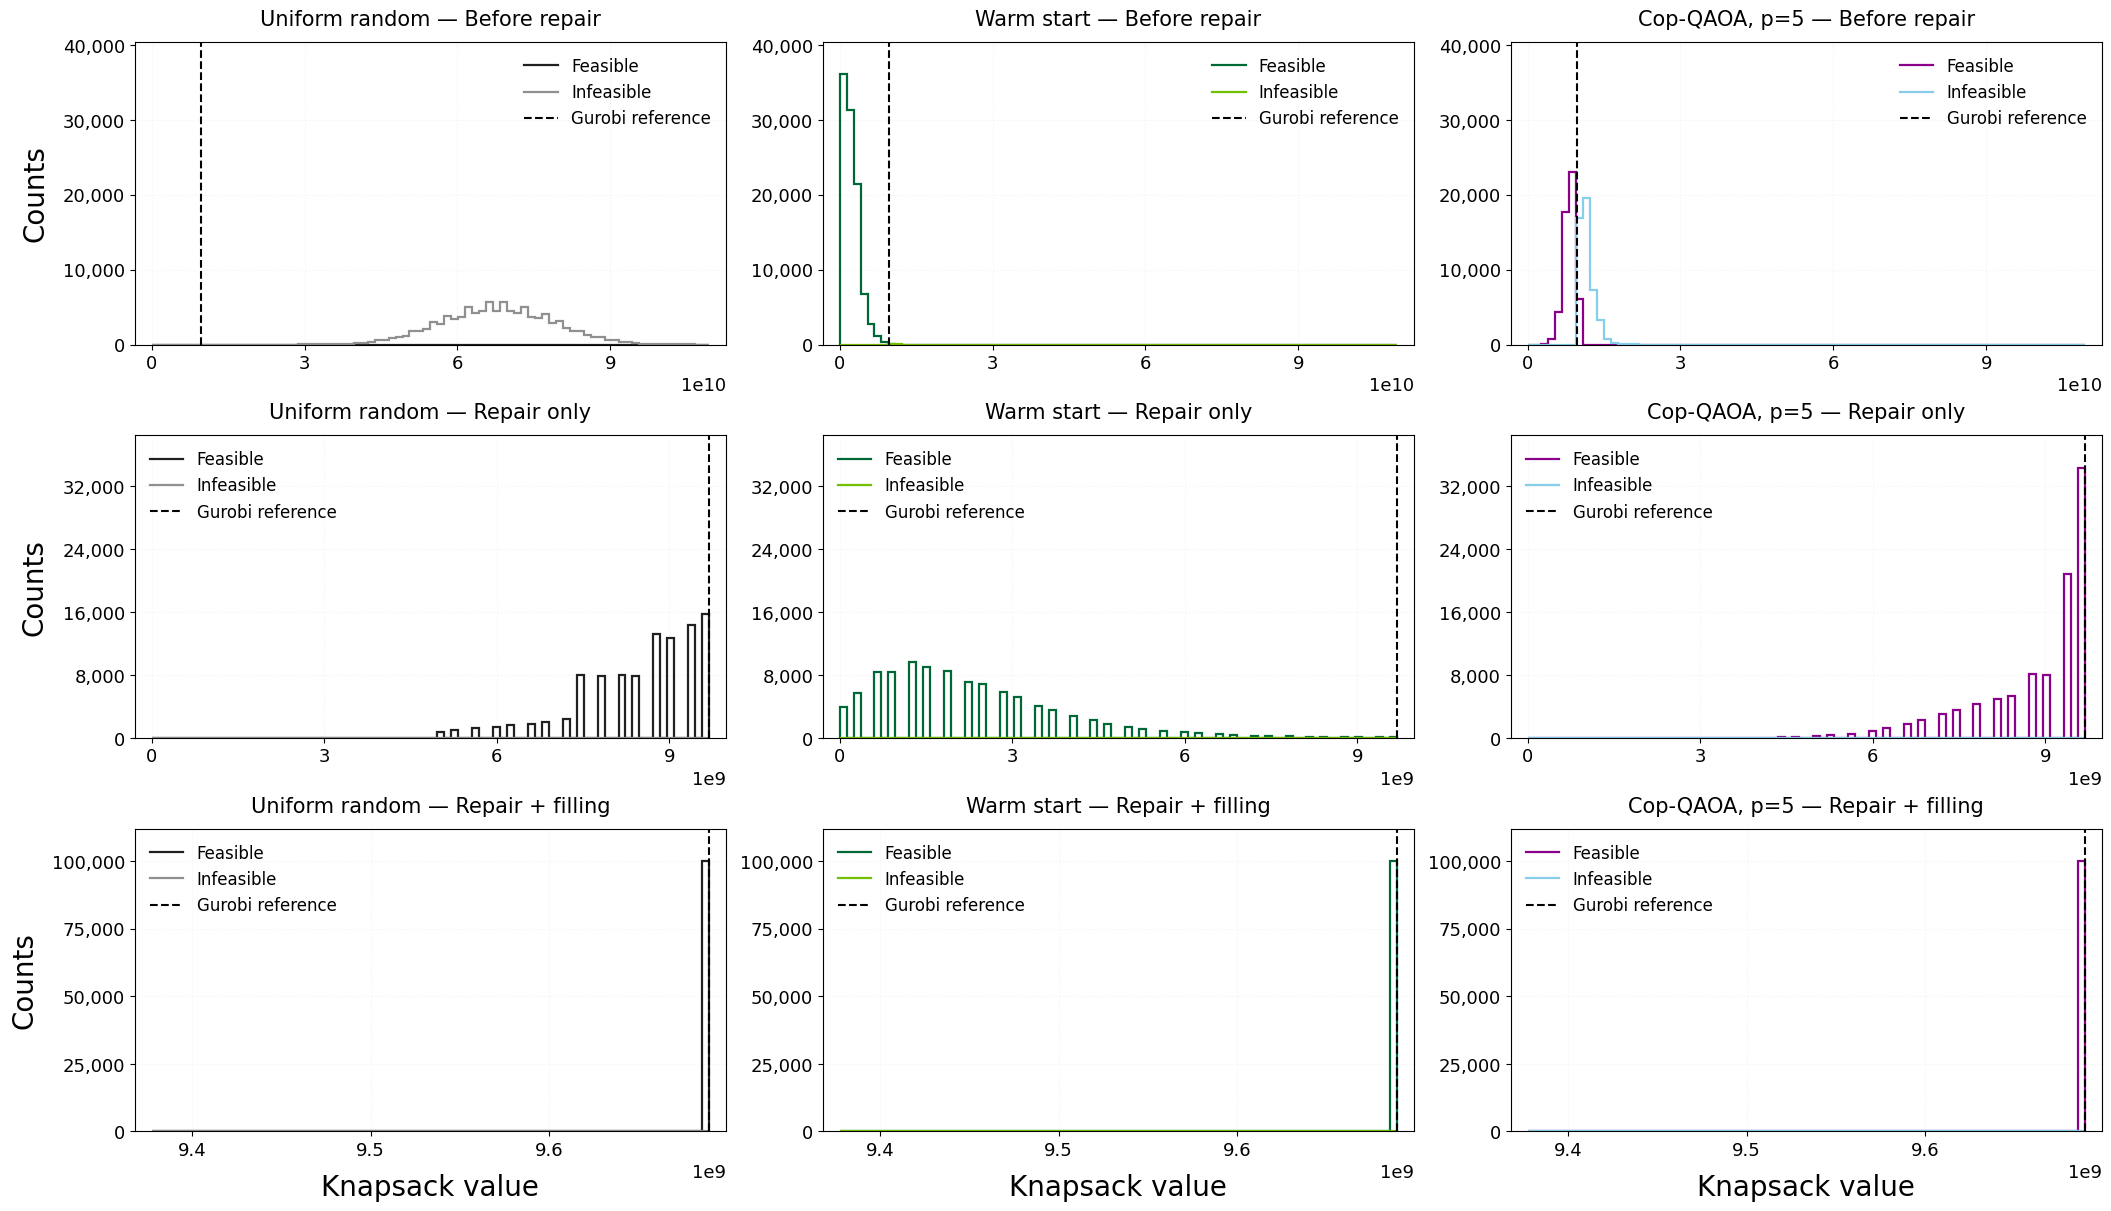

In [16]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import (
    MaxNLocator,
    ScalarFormatter,
    StrMethodFormatter,
)

# ------------------------------------------------------------
# Saved results — no training or hardware jobs are rerun
# ------------------------------------------------------------
PROJECT_ROOT = Path("/Users/naeimeh/Downloads/Copula_QAOA")

RUN_NAME = (
    'final_100_items'
)

SAVED_FILE = (
    PROJECT_ROOT / "results" / RUN_NAME
    / "postprocessing_comparison.json"
)

if not SAVED_FILE.is_file():
    raise FileNotFoundError(f"Saved results not found:\n{SAVED_FILE}")

data = json.loads(SAVED_FILE.read_text())
distributions = data["distributions"]
reference = data.get("reference_value")
reference = None if reference is None else float(reference)
depth = data["final_depth"]

print(f"Reading: {SAVED_FILE}")
print(f"Saved QAOA depth: p={depth}")

# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------
N_BINS = 80

# None displays all samples.
# To zoom the entire bottom row, instead use:
# COMPLETION_X_RANGE = (9_688_000_000, 9_690_000_000)
# Samples outside the zoom are explicitly reported.
COMPLETION_X_RANGE = None

stages = [
    ("before", "Before repair"),
    ("repair", "Repair only"),
    ("complete", "Repair + filling"),
]

methods = [
    ("random", "Uniform random"),
    ("warm", "Warm start"),
    ("qaoa", f"Cop-QAOA, p={depth}"),
]

# Each pair is (feasible, infeasible).
colours = {
    "random": ("#202020", "#909090"),
    "warm": ("#006837", "#73C000"),
    "qaoa": ("darkmagenta", "skyblue"),
}

fig, axes = plt.subplots(
    3, 3,
    figsize=(21, 12),
    sharex="row",
    sharey="row",
    constrained_layout=True,
)

for row, (stage, stage_title) in enumerate(stages):

    # Common histogram bins within this row.
    row_values = [
        float(value)
        for method, _ in methods
        for field in ("feasible_by_value", "infeasible_by_value")
        for value, count in distributions[f"{method}_{stage}"][field].items()
        if count > 0
    ]

    if not row_values:
        raise ValueError(f"No saved samples for {stage}")

    zoomed = (
        stage == "complete"
        and COMPLETION_X_RANGE is not None
    )

    if zoomed:
        lo, hi = COMPLETION_X_RANGE
        if hi <= lo:
            raise ValueError(
                "COMPLETION_X_RANGE must have upper > lower."
            )
    else:
        lo, hi = min(row_values), max(row_values)

    if lo == hi:
        padding = max(abs(lo) * 1e-9, 1.0)
        lo -= padding
        hi += padding

    edges = np.linspace(lo, hi, N_BINS + 1)
    row_peak = 0.0

    for col, (method, method_title) in enumerate(methods):
        ax = axes[row, col]
        summary = distributions[f"{method}_{stage}"]
        outside_count = 0

        for field, label, colour in [
            ("feasible_by_value", "Feasible", colours[method][0]),
            ("infeasible_by_value", "Infeasible", colours[method][1]),
        ]:
            histogram = summary[field]

            values = np.asarray(
                [float(value) for value in histogram],
                dtype=float,
            )
            counts = np.asarray(
                list(histogram.values()),
                dtype=float,
            )

            heights, _ = np.histogram(
                values,
                bins=edges,
                weights=counts,
            )

            outside = counts[
                (values < lo) | (values > hi)
            ].sum()
            outside_count += int(outside)

            if not np.isclose(
                heights.sum() + outside,
                counts.sum(),
            ):
                raise ValueError(
                    f"Count mismatch: {method}_{stage}, {label}"
                )

            # Continuous step outline, without filling.
            ax.stairs(
                heights,
                edges,
                fill=False,
                color=colour,
                linewidth=1.6,
                label=label,
            )

            row_peak = max(
                row_peak,
                float(heights.max()),
            )

        if reference is not None:
            ax.axvline(
                reference,
                color="black",
                linestyle="--",
                linewidth=1.5,
                label="Gurobi reference",
            )

        valid = sum(summary["feasible_by_value"].values())
        invalid = sum(summary["infeasible_by_value"].values())

        print(
            f"{method_title} — {stage_title}: "
            f"feasible={valid:,}, "
            f"infeasible={invalid:,}, "
            f"total={valid + invalid:,}, "
            f"outside view={outside_count:,}"
        )

        if zoomed:
            ax.text(
                0.03, 0.55,
                f"Zoomed view\n"
                f"{outside_count:,} samples outside view",
                transform=ax.transAxes,
                fontsize=11,
            )

        # Single-line panel titles.
        ax.set_title(
            f"{method_title} — {stage_title}",
            fontsize=15,
            pad=12,
        )

        # X-axis label only in the bottom row.
        ax.set_xlabel(
            "Knapsack value" if row == 2 else "",
            fontsize=20,
            labelpad=10,
        )

        if col == 0:
            ax.set_ylabel(
                "Counts",
                fontsize=20,
                labelpad=10,
            )

        ax.tick_params(
            axis="both",
            labelsize=13,
            labelleft=True,
            labelbottom=True,
        )

        ax.legend(frameon=False, fontsize=12)
        ax.grid(alpha=0.15, linestyle=":")
        ax.set_axisbelow(True)

    # Shared x- and y-limits within this row only.
    display_lo, display_hi = lo, hi

    if not zoomed and reference is not None:
        display_lo = min(display_lo, reference)
        display_hi = max(display_hi, reference)

    padding = max(
        (display_hi - display_lo) * 0.03,
        1.0,
    )

    for ax in axes[row]:
        ax.set_xlim(
            display_lo - padding,
            display_hi + padding,
        )
        ax.set_ylim(
            0,
            max(1.0, row_peak * 1.12),
        )

        ax.xaxis.set_major_locator(MaxNLocator(4))

        formatter = ScalarFormatter(useOffset=False)
        formatter.set_powerlimits((0, 0))
        ax.xaxis.set_major_formatter(formatter)

        ax.yaxis.set_major_locator(
            MaxNLocator(5, integer=True)
        )
        ax.yaxis.set_major_formatter(
            StrMethodFormatter("{x:,.0f}")
        )

        ax.xaxis.get_offset_text().set_fontsize(13)
        ax.yaxis.get_offset_text().set_fontsize(13)

plt.show()

Loading saved results from /Users/naeimeh/Downloads/release_build/results/n_100_c_10000000000_g_5_f_0.3_eps_1e-05_s_300_20260914_140101


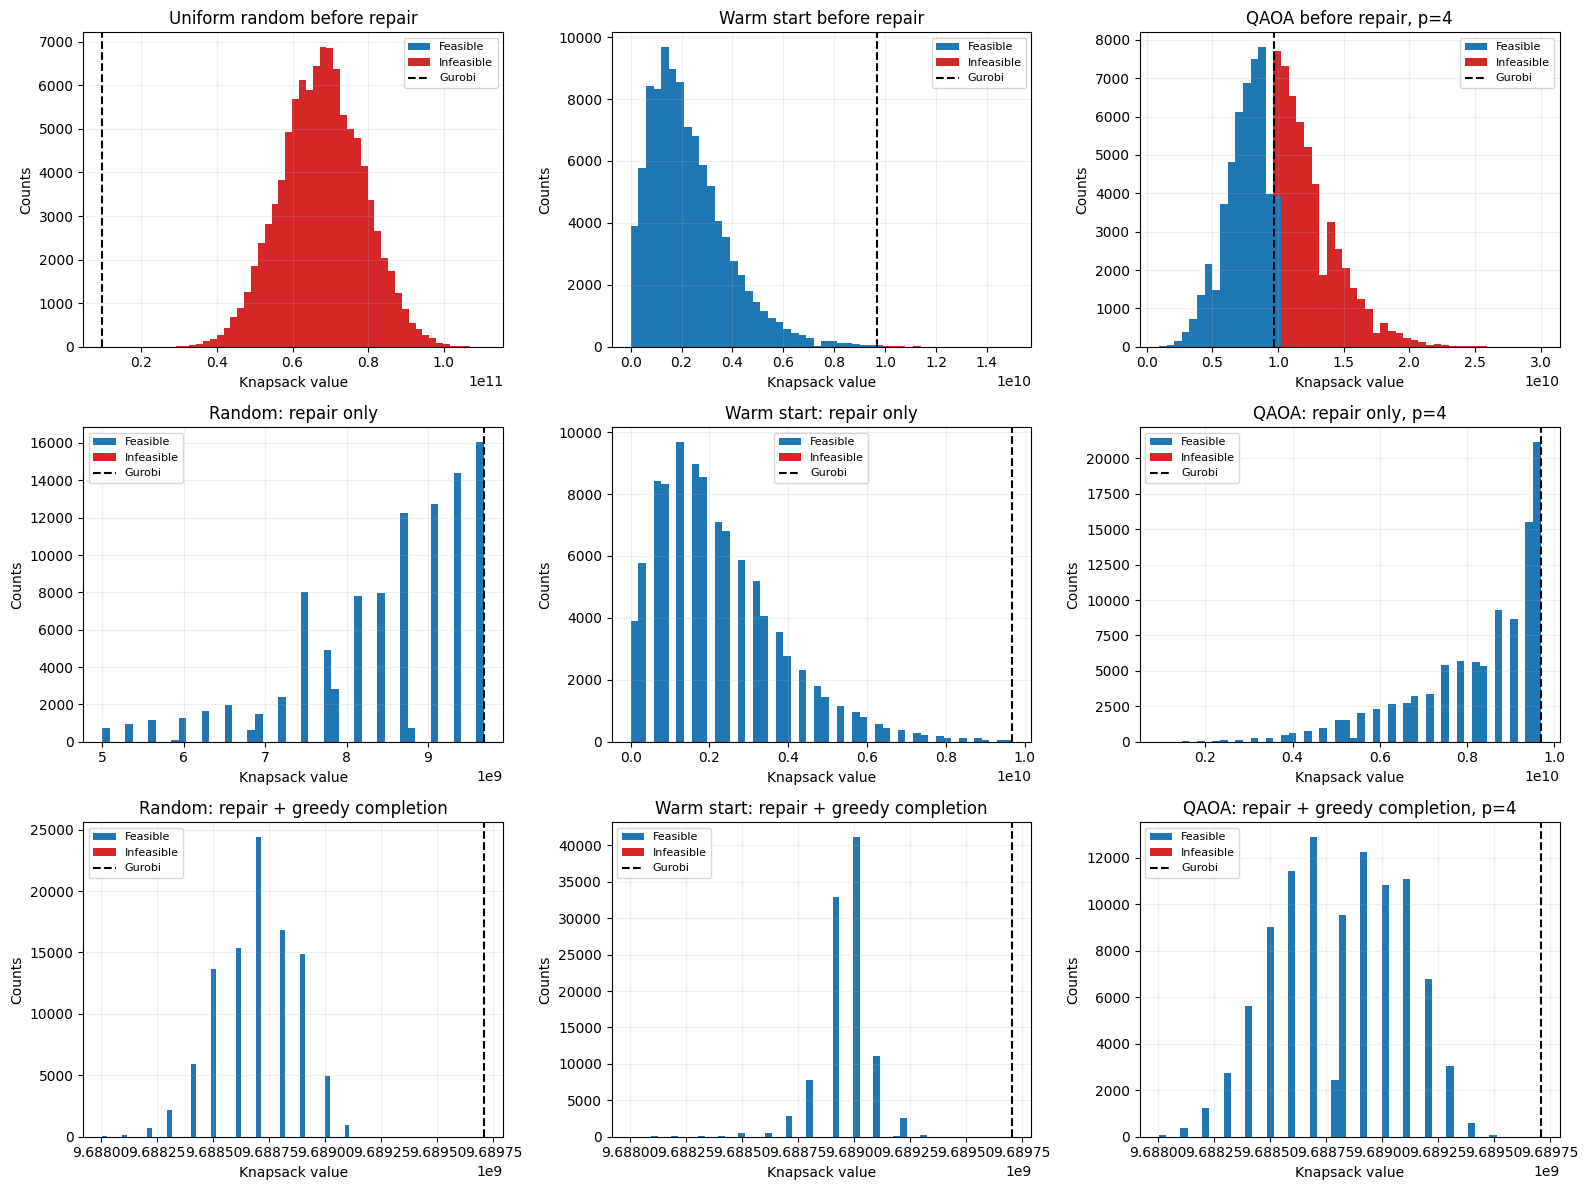

In [14]:
from pathlib import Path
import matplotlib.pyplot as plt
from copula_qaoa.artifacts import latest_result_directory, plot_saved_postprocessing

PROJECT_ROOT = Path('/Users/naeimeh/Downloads/Copula_QAOA')
SAVED_RESULTS_DIR = PROJECT_ROOT / "results" / "final_100_items"
# SAVED_RESULTS_DIR = PROJECT_ROOT / "results" / "your_run_directory"

print(f"Loading saved results from {SAVED_RESULTS_DIR}")
plot_saved_postprocessing(SAVED_RESULTS_DIR / "postprocessing_comparison.json")
plt.show()


In [16]:
# AR for the existing smoothed lazy-greedy warm-start samples (before repair).
# Run after the comparison sampling cell. No new random samples are generated.
import numpy as np

if reference is None or reference["value"] <= 0:
    raise ValueError("A positive Gurobi reference value is required.")

warm_ar_values, _, warm_ar_feasible = evaluate_samples(
    warm_samples_ordered, ordered_values, ordered_weights, instance.capacity
)
warm_ar_sorted = np.sort(warm_ar_values[warm_ar_feasible])[::-1]
warm_ar_limit = AR_MAX_SAMPLES  # Same best-valid-shot limit as QAOA; None means all.
if warm_ar_limit is not None and (
    not isinstance(warm_ar_limit, (int, np.integer)) or warm_ar_limit <= 0
):
    raise ValueError("AR_MAX_SAMPLES must be a positive integer or None.")
warm_ar_selected = warm_ar_sorted if warm_ar_limit is None else warm_ar_sorted[:warm_ar_limit]
warm_ar_all = (
    float(warm_ar_sorted.mean() / reference["value"]) if warm_ar_sorted.size else np.nan
)
warm_ar_top = (
    float(warm_ar_selected.mean() / reference["value"]) if warm_ar_selected.size else np.nan
)
print("Smoothed lazy greedy / warm start, before repair (existing samples)")
print(f"Total shots: {len(warm_ar_values):,}; valid shots: {len(warm_ar_sorted):,}")
print(f"Valid ratio: {warm_ar_feasible.mean():.6f}" if len(warm_ar_values) else "No samples")
print(f"AR, all valid shots: {warm_ar_all:.6f}")
print(f"AR, best up to {warm_ar_limit} valid shots: {warm_ar_top:.6f}; used: {len(warm_ar_selected):,}")
print(f"Best feasible value: {warm_ar_sorted[0] if warm_ar_sorted.size else None}")
# This is relative to the Gurobi incumbent unless its optimality is certified.


Smoothed lazy greedy / warm start, before repair (existing samples)
Total shots: 100,000; valid shots: 99,900
Valid ratio: 0.999000
AR, all valid shots: 0.228327
AR, best up to 20000 valid shots: 0.485296; used: 20,000
Best feasible value: 9688504240


In [18]:
# 1. Submit trained circuits directly to IBM (without Q-CTRL).
# Set True only when you want to submit a NEW hardware job.
RUN_IBM_HARDWARE = True

if RUN_IBM_HARDWARE:
    from qiskit_ibm_runtime import SamplerV2 as RuntimeSampler, SamplerOptions
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    from pathlib import Path

    ibm_backend = service.backend("ibm_phoenix")
    ibm_shots = 100_000
    ibm_depths = sorted(training_results)
    ibm_pm = generate_preset_pass_manager(
        backend=ibm_backend, optimization_level=3, seed_transpiler=111,
    )
    ibm_circuits = []
    for depth in ibm_depths:
        circuit = training_results[depth].circuit.copy()
        circuit.measure_all()
        ibm_circuits.append(ibm_pm.run(circuit))

    # Error-suppression options from your original notebook.
    ibm_options = SamplerOptions()
    ibm_options.dynamical_decoupling.enable = True
    ibm_options.dynamical_decoupling.sequence_type = "XpXm"
    ibm_options.twirling.enable_measure = True
    ibm_sampler = RuntimeSampler(mode=ibm_backend, options=ibm_options)
    ibm_job = ibm_sampler.run(ibm_circuits, shots=ibm_shots)
    print("IBM job ID:", ibm_job.job_id())
    ibm_output_dir = Path(RESULTS_DIR) / "hardware" / ("ibm_without_qctrl_" + ibm_job.job_id())
    ibm_output_dir.mkdir(parents=True, exist_ok=True)
else:
    print("IBM submission disabled. Set RUN_IBM_HARDWARE=True to submit.")


IBM job ID: dao0rblr85ps73fekvmg


In [19]:
# 2. Retrieve IBM results. This does NOT submit another job.
# job.result() waits if the job is still queued/running.
FETCH_IBM_RESULTS = True

if FETCH_IBM_RESULTS:
    import json
    from copula_qaoa.training import extract_counts, approximation_ratio
    from copula_qaoa.knapsack import evaluate_counts

    ibm_result = ibm_job.result()
    ibm_evaluation = {}
    for depth, pub_result in zip(ibm_depths, ibm_result):
        counts = extract_counts(pub_result)
        summary = evaluate_counts(counts, ordered_values, ordered_weights, instance.capacity)
        ibm_evaluation[depth] = {"counts": counts, "summary": summary}
        ar, used = (float("nan"), 0) if reference is None else approximation_ratio(
            summary.feasible_by_value, reference["value"],
            max_samples=globals().get("AR_MAX_SAMPLES", None),
        )
        (ibm_output_dir / f"counts_p{depth}.json").write_text(json.dumps(counts, indent=2))
        print(f"p={depth}: AR={ar:.6f}, AR valid shots={used}, "
              f"best={summary.best_feasible_value}, valid ratio={summary.feasible_probability:.4f}")
else:
    print("Set FETCH_IBM_RESULTS=True after submitting the IBM job.")


p=1: AR=0.879592, AR valid shots=20000, best=9689105174, valid ratio=0.6252
p=2: AR=0.840433, AR valid shots=20000, best=9689204300, valid ratio=0.2503
p=3: AR=0.856119, AR valid shots=8818, best=9689205263, valid ratio=0.0882
p=4: AR=0.854904, AR valid shots=8656, best=9689505921, valid ratio=0.0866
p=5: AR=0.895015, AR valid shots=2325, best=9689405718, valid ratio=0.0232


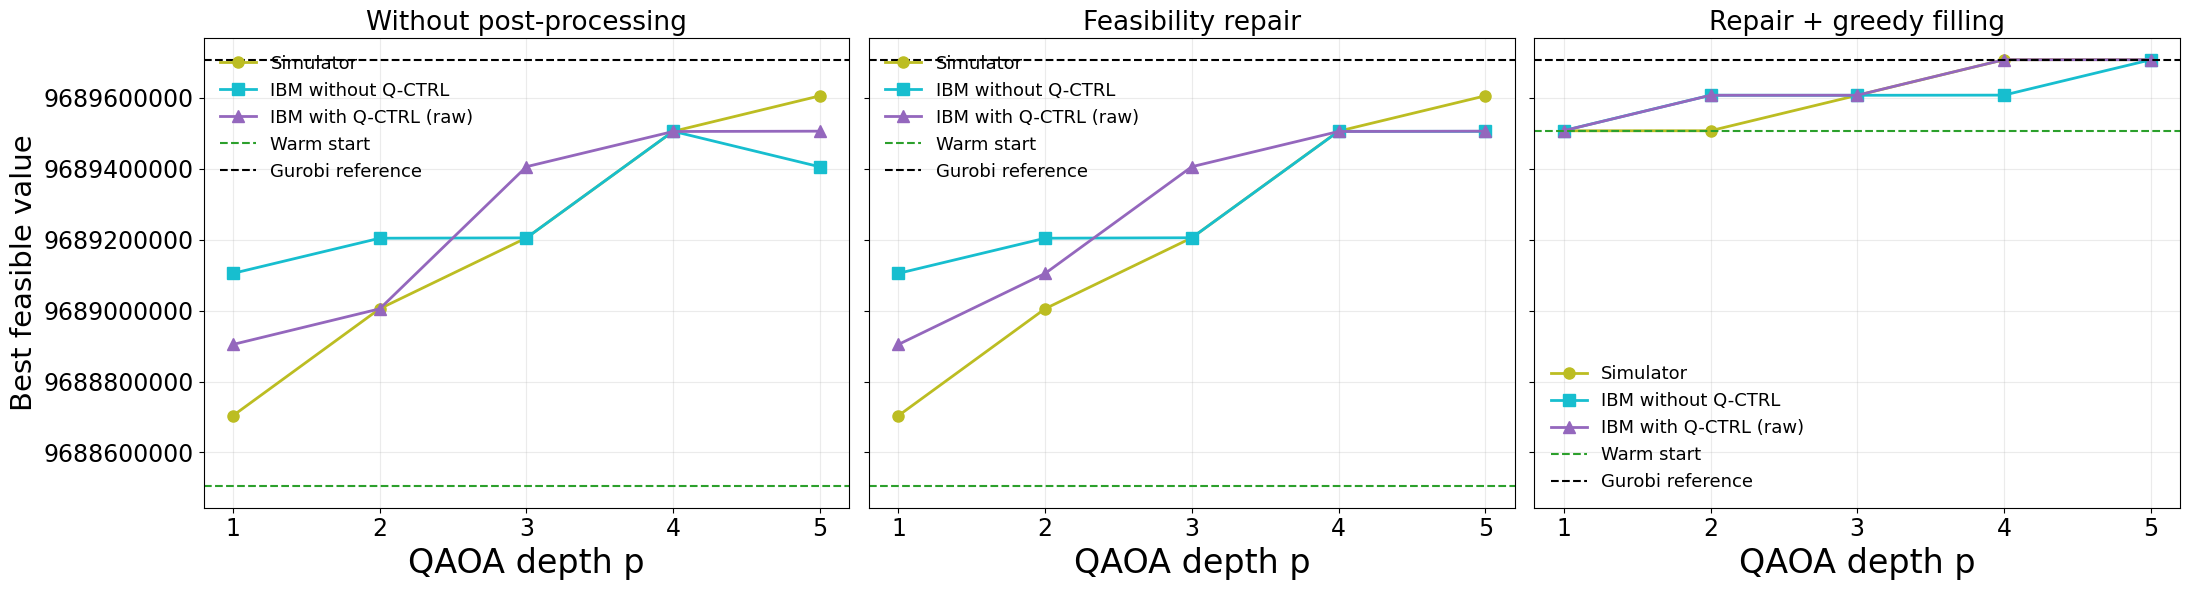

In [86]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt

# Select the repository containing the FINAL saved 100-item experiment.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "copula_qaoa").is_dir()
     and (p / "results" / "final_100_items" / "analysis" / "summary.json").is_file()),
    Path("/Users/naeimeh/Downloads/Copula_QAOA"),
)
sys.path.insert(0, str(PROJECT_ROOT))
from copula_qaoa.final_results import load_final_results, plot_final_results
RUN_DIR = PROJECT_ROOT / "results" / "final_100_items"
saved_results = load_final_results(RUN_DIR)

# Reads the cached values: does NOT repair samples, run a simulator or contact IBM.
fig, axes = plot_final_results(RUN_DIR, metric="best_value")
plt.show()


Saved PDF: /Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items/plots/best_values_before_and_after_filling.pdf


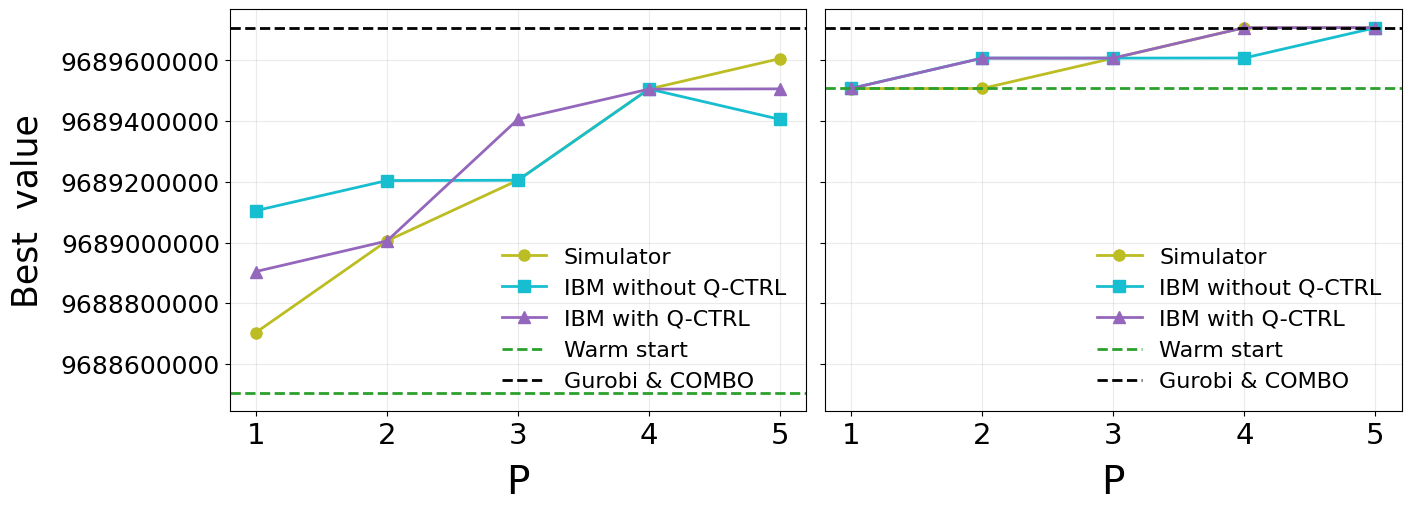

In [132]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

RUN_DIR = Path(
    "/Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items"
)
data = json.loads((RUN_DIR / "analysis" / "summary.json").read_text())

colours = ["tab:olive", "tab:cyan", "tab:purple"]
markers = ["o", "s", "^"]

panels = [
    ("before", "Before post-processing"),
    ("completion", "Repair + greedy filling"),
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True,
    layout="constrained",
)

# Common limits include all displayed values and reference lines.
displayed_values = [data["reference"]["value"]]

for stage, _ in panels:
    for depths in data["series"].values():
        displayed_values.extend(
            result[stage]["best_value"]
            for result in depths.values()
            if result[stage]["best_value"] is not None
        )

    warm = data["baselines"]["warm_start"][stage]["best_value"]
    if warm is not None:
        displayed_values.append(warm)

y_min = min(displayed_values)
y_max = max(displayed_values)
padding = 0.05 * (y_max - y_min) if y_max > y_min else 1.0

for ax, (stage, title) in zip(axes, panels):
    all_depths = set()

    for (label, depths), colour, marker in zip(
        data["series"].items(), colours, markers
    ):
        ps = sorted(map(int, depths))
        all_depths.update(ps)

        values = [
            depths[str(p)][stage]["best_value"]
            for p in ps
        ]

        ax.plot(
            ps,
            [float("nan") if value is None else value for value in values],
            color=colour,
            marker=marker,
            linewidth=2,
            markersize=8,
            label=label.replace(" (raw)", ""),
        )

    warm = data["baselines"]["warm_start"][stage]["best_value"]
    if warm is not None:
        ax.axhline(
            warm,
            color="tab:green",
            linestyle="--",
            linewidth=2,
            label="Warm start",
        )

    ax.axhline(
        data["reference"]["value"],
        color="black",
        linestyle="--",
        linewidth=2,
        label="Gurobi & COMBO",
    )

    #ax.set_title(title, fontsize=22, pad=12)
    ax.set_xlabel("P", fontsize=28, labelpad=10)
    ax.set_xticks(sorted(all_depths))
    ax.set_ylim(y_min - padding, y_max + padding)

    ax.tick_params(axis="x", labelsize=21)
    ax.tick_params(axis="y", labelsize=18)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(alpha=0.25)

    ax.legend(
        loc="lower right",
        fontsize=16,
        frameon=False,
    )

axes[0].set_ylabel("Best  value", fontsize=25, labelpad=12)

# Hide only the second panel's y-axis numbers; retain tick marks.
axes[1].tick_params(axis="y", labelleft=False)
axes[1].set_ylabel("")

OUTPUT_DIR = RUN_DIR / "plots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pdf_path = OUTPUT_DIR / "best_values_before_and_after_filling.pdf"
fig.savefig(pdf_path, bbox_inches="tight", transparent=True)

print(f"Saved PDF: {pdf_path}")
plt.show()

Ratio calculated over all feasible shots.
Infeasible shots are excluded; the reference is not a proven optimum.
Saved PDF: /Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items/plots/approximation_ratio_before_postprocessing.pdf


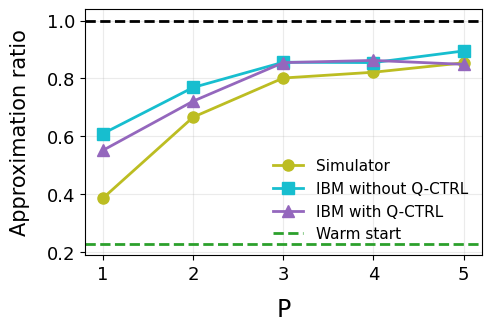

In [109]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

RUN_DIR = Path(
    "/Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items"
)
data = json.loads((RUN_DIR / "analysis" / "summary.json").read_text())

# Choose 8_000, 20_000, or None for all feasible shots.
AR_TOP_K = None

metrics = {
    8_000: "ar_top8000",
    20_000: "ar_top20000",
    None: "ar_all_feasible",
}
if AR_TOP_K not in metrics:
    raise ValueError("Choose AR_TOP_K = 8000, 20000, or None.")

metric = metrics[AR_TOP_K]
colours = ["tab:olive", "tab:cyan", "tab:purple"]
markers = ["o", "s", "^"]

fig, ax = plt.subplots(figsize=(4.8, 3.2), layout="constrained")
all_depths = set()

for (label, depths), colour, marker in zip(
    data["series"].items(), colours, markers
):
    ps = sorted(map(int, depths))
    all_depths.update(ps)
    ratios = [
        depths[str(p)]["before"][metric]
        for p in ps
    ]

    ax.plot(
        ps,
        [float("nan") if value is None else value for value in ratios],
        color=colour,
        marker=marker,
        linewidth=2,
        markersize=8,
        label=label.replace(" (raw)", ""),
    )

warm = data["baselines"]["warm_start"]["before"][metric]
if warm is not None:
    ax.axhline(
        warm,
        color="tab:green",
        linestyle="--",
        linewidth=2,
        label="Warm start",
    )

ax.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=2,
    #label="Gurobi reference",
)

#ax.set_title("Before post-processing", fontsize=22, pad=12)
ax.set_xlabel("P", fontsize=17, labelpad=10)
ax.set_ylabel(
    "Approximation ratio",
    fontsize=15,
    labelpad=12,
)
ax.set_xticks(sorted(all_depths))
ax.tick_params(axis="both", labelsize=13)
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.grid(alpha=0.25)
ax.legend(loc="lower right", fontsize=11, frameon=False)

OUTPUT_DIR = RUN_DIR / "plots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pdf_path = OUTPUT_DIR / "approximation_ratio_before_postprocessing.pdf"
fig.savefig(pdf_path, bbox_inches="tight", transparent=True)

selection = (
    "all feasible shots"
    if AR_TOP_K is None
    else f"best up to {AR_TOP_K:,} feasible shots"
)
print(f"Ratio calculated over {selection}.")
print("Infeasible shots are excluded; the reference is not a proven optimum.")
print(f"Saved PDF: {pdf_path}")

plt.show()

Cop-QAOA, P=5: feasible=51,971, infeasible=48,029, total=100,000, feasible fraction=51.971%
Best feasible value: 9,689,605,918
PDF saved to:
/Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items/plots/distributions/distribution_simulator_p5.pdf



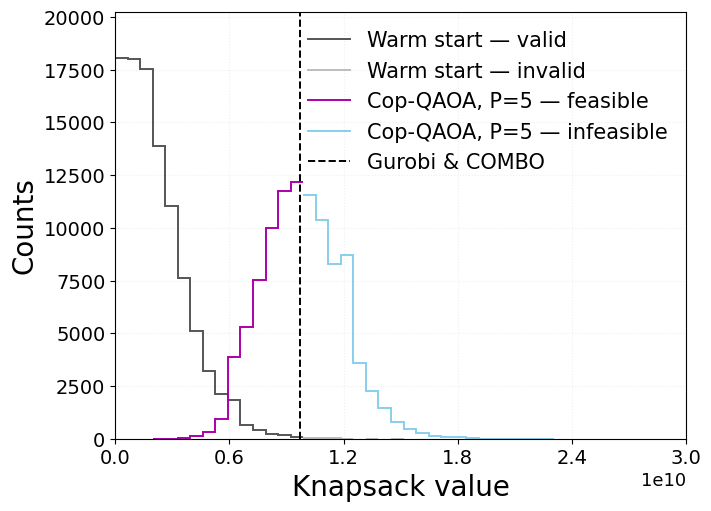

IBM, P=1: feasible=62,519, infeasible=37,481, total=100,000, feasible fraction=62.519%
Best feasible value: 9,689,105,174
Note: 333 shots lie outside the displayed x-axis range; they remain in the saved data.
PDF saved to:
/Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items/plots/distributions/distribution_ibm_without_qctrl_p1.pdf



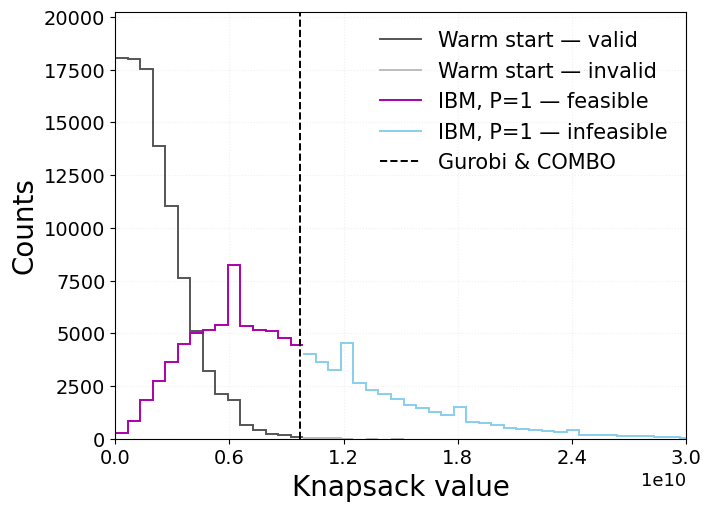

Q-CTRL, P=5: feasible=40,490, infeasible=59,510, total=100,000, feasible fraction=40.490%
Best feasible value: 9,689,506,266
Note: 5 shots lie outside the displayed x-axis range; they remain in the saved data.
IBM, P=5: feasible=2,325, infeasible=97,675, total=100,000, feasible fraction=2.325%
Best feasible value: 9,689,405,718
Note: 13,911 shots lie outside the displayed x-axis range; they remain in the saved data.
PDF saved to:
/Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items/plots/distributions/distribution_ibm_with_and_without_qctrl_p5.pdf



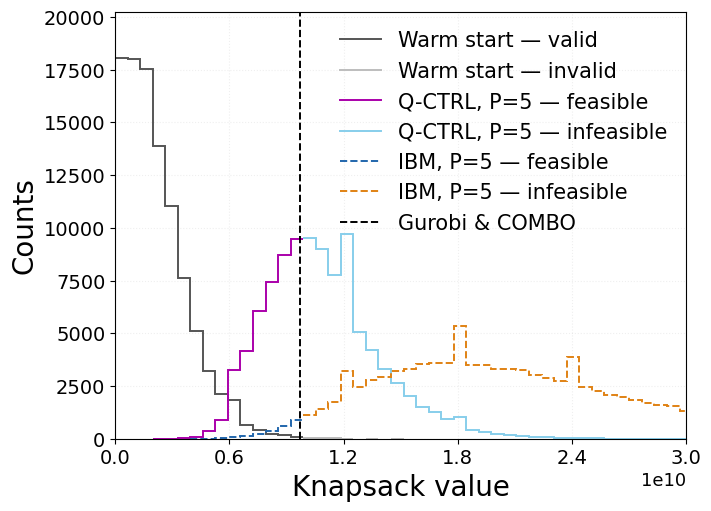

In [142]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, ScalarFormatter

# ------------------------------------------------------------
# Read saved results only.
# ------------------------------------------------------------
RUN_DIR = Path(
    "/Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items"
)

OUTPUT_DIR = RUN_DIR / "plots" / "distributions"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

saved = json.loads(
    (RUN_DIR / "analysis" / "distributions.json").read_text()
)
baselines = json.loads(
    (RUN_DIR / "postprocessing_comparison.json").read_text()
)

warm_summary = baselines["distributions"]["warm_before"]
gurobi_value = baselines["reference_value"]

simulator_summary = saved["series"]["Simulator"]["5"]["before"]
ibm_p1_summary = saved["series"]["IBM without Q-CTRL"]["1"]["before"]
ibm_p5_summary = saved["series"]["IBM without Q-CTRL"]["5"]["before"]
qctrl_p5_summary = saved["series"]["IBM with Q-CTRL (raw)"]["5"]["before"]

# Same outline style as your example.
N_BINS = 120
HIDE_EMPTY_BINS = True  # Matches your example; empty bins create gaps.

fields = ("feasible_by_value", "infeasible_by_value")
all_summaries = [
    warm_summary,
    simulator_summary,
    ibm_p1_summary,
    ibm_p5_summary,
    qctrl_p5_summary,
]

# Shared bin edges for all three figures.
all_values = [
    float(value)
    for summary in all_summaries
    for field in fields
    for value, count in summary[field].items()
    if count > 0
]

if not all_values:
    raise ValueError("The saved distributions contain no samples.")

lo, hi = min(all_values), max(all_values)
if lo == hi:
    lo, hi = lo - 0.5, hi + 0.5

edges = np.linspace(lo, hi, N_BINS + 1)


def histogram_counts(summary, field):
    entries = [
        (float(value), int(count))
        for value, count in summary[field].items()
        if count > 0
    ]

    if not entries:
        return np.zeros(N_BINS, dtype=float)

    values, counts = zip(*entries)
    heights, _ = np.histogram(
        values,
        bins=edges,
        weights=np.asarray(counts, dtype=np.int64),
    )

    if int(heights.sum()) != sum(counts):
        raise ValueError("Some samples fall outside the histogram bins.")

    return heights.astype(float)


common_peak = max(
    histogram_counts(summary, field).max()
    for summary in all_summaries
    for field in fields
)
common_ymax = max(1.0, common_peak * 1.12)


def print_summary(label, summary):
    feasible = sum(summary["feasible_by_value"].values())
    infeasible = sum(summary["infeasible_by_value"].values())
    total = feasible + infeasible

    fraction = feasible / total if total else float("nan")
    best = max(
        (
            float(value)
            for value, count in summary["feasible_by_value"].items()
            if count > 0
        ),
        default=None,
    )

    print(
        f"{label}: feasible={feasible:,}, "
        f"infeasible={infeasible:,}, total={total:,}, "
        f"feasible fraction={fraction:.3%}"
    )
    print(
        "Best feasible value:",
        f"{best:,.0f}" if best is not None else "None",
    )


def plot_distribution(methods, filename):
    fig, ax = plt.subplots(
        figsize=(7, 5),
        constrained_layout=True,
    )

    curves = [
        (
            warm_summary, "feasible_by_value",
            "#555555", "Warm start — valid", "-"
        ),
        (
            warm_summary, "infeasible_by_value",
            "#BDBDBD", "Warm start — invalid", "-"
        ),
    ]

    for summary, label, feasible_colour, infeasible_colour, style in methods:
        curves.extend([
            (
                summary, "feasible_by_value",
                feasible_colour, f"{label} — feasible", style
            ),
            (
                summary, "infeasible_by_value",
                infeasible_colour, f"{label} — infeasible", style
            ),
        ])

    for summary, field, colour, label, style in curves:
        heights = histogram_counts(summary, field)

        if HIDE_EMPTY_BINS:
            heights[heights == 0] = np.nan

        ax.stairs(
            heights,
            edges,
            baseline=None,
            fill=False,
            color=colour,
            linewidth=1.4,
            linestyle=style,
            label=label,
        )

    if gurobi_value is not None:
        ax.axvline(
            float(gurobi_value),
            color="black",
            linestyle="--",
            linewidth=1.4,
            label="Gurobi & COMBO",
        )

    ax.set_xlim(0, 3e10)
    ax.set_ylim(0, common_ymax)

    ax.set_xlabel("Knapsack value", fontsize=20)
    ax.set_ylabel("Counts", fontsize=20)
    # No title.

    ax.tick_params(axis="both", labelsize=14)
    ax.xaxis.set_major_locator(MaxNLocator(5))

    formatter = ScalarFormatter(useOffset=False)
    formatter.set_powerlimits((0, 0))
    ax.xaxis.set_major_formatter(formatter)
    ax.xaxis.get_offset_text().set_fontsize(13)

    ax.legend(
        frameon=False,
        fontsize=15,
        loc="upper right",
    )
    ax.grid(alpha=0.2, linestyle=":")
    ax.set_axisbelow(True)

    for summary, label, *_ in methods:
        print_summary(label, summary)

        outside = sum(
            count
            for field in fields
            for value, count in summary[field].items()
            if float(value) < 0 or float(value) > 3e10
        )
        if outside:
            print(
                f"Note: {outside:,} shots lie outside the displayed "
                "x-axis range; they remain in the saved data."
            )

    pdf_path = OUTPUT_DIR / filename
    fig.savefig(
        pdf_path,
        format="pdf",
        bbox_inches="tight",
        transparent=True,
    )

    print(f"PDF saved to:\n{pdf_path}\n")
    plt.show()


# ------------------------------------------------------------
# 1. Simulator, p=5.
# ------------------------------------------------------------
plot_distribution(
    methods=[
        (
            simulator_summary,
            "Cop-QAOA, P=5",
            "#AA00AA",
            "#87CEEB",
            "-",
        ),
    ],
    filename="distribution_simulator_p5.pdf",
)

# ------------------------------------------------------------
# 2. IBM without Q-CTRL, p=1.
# ------------------------------------------------------------
plot_distribution(
    methods=[
        (
            ibm_p1_summary,
            "IBM, P=1",
            "#AA00AA",
            "#87CEEB",
            "-",
        ),
    ],
    filename="distribution_ibm_without_qctrl_p1.pdf",
)

# ------------------------------------------------------------
# 3. IBM with and without Q-CTRL, p=5.
#    Q-CTRL: purple/cyan solid lines.
#    Direct IBM: blue/orange dashed lines.
# ------------------------------------------------------------
plot_distribution(
    methods=[
        (
            qctrl_p5_summary,
            "Q-CTRL, P=5",
            "#AA00AA",
            "#87CEEB",
            "-",
        ),
        (
            ibm_p5_summary,
            "IBM, P=5",
            "#2166AC",
            "#E08214",
            "--",
        ),
    ],
    filename="distribution_ibm_with_and_without_qctrl_p5.pdf",
)

In [130]:
import re
from qiskit_ibm_runtime import QiskitRuntimeService

# Reuse your existing token without printing it.
token = service.active_account()["token"]

INSTANCE_P1_P5 = (
    "crn:v1:bluemix:public:quantum-computing:us-east:a/8f99915aec1d4742b2a6a9408b74a1af:e7eca02c-ee10-4326-94a7-d7a3dc9e78cb::"
)

INSTANCE_P2_P3_P4 = (
    "crn:v1:bluemix:public:quantum-computing:us-east:a/8f99915aec1d4742b2a6a9408b74a1af:5e49230c-df9f-4142-be46-96ac857249bd::"
)

jobs = [
    (INSTANCE_P1_P5, "dbdjh7hgv2cc73doiv6g"),
    (INSTANCE_P2_P3_P4, "dbdmda9gv2cc73donib0"),
]

def is_two_qubit_gate(instruction):
    return (
        instruction.operation.num_qubits == 2
        and instruction.operation.name
        not in {"barrier", "measure", "reset"}
    )

rows = []

for instance_crn, job_id in jobs:
    connection = QiskitRuntimeService(
        token=token,
        instance=instance_crn,
        channel="ibm_quantum_platform",
    )

    job = connection.job(job_id)

    for pub in job.inputs.get("pubs", []):
        circuit = getattr(pub, "circuit", None)
        if circuit is None and isinstance(pub, (tuple, list)):
            circuit = pub[0]

        if circuit is None or not hasattr(circuit, "count_ops"):
            continue

        match = re.search(r"copula_qaoa_p(\d+)", circuit.name)
        if match is None:
            continue  # Exclude calibration circuits.

        rows.append((
            int(match.group(1)),
            circuit.depth(),
            circuit.depth(filter_function=is_two_qubit_gate),
            sum(is_two_qubit_gate(inst) for inst in circuit.data),
        ))

print(f"{'P':>3} {'Circuit depth':>15} {'2Q depth':>12} {'2Q gate count':>15}")
for p, depth, depth_2q, count_2q in sorted(rows):
    print(f"{p:>3} {depth:>15} {depth_2q:>12} {count_2q:>15}")

qiskit_runtime_service._discover_account:WARNING:2026-10-24 19:25:48,364: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service._discover_account:WARNING:2026-10-24 19:25:53,022: Loading account with the given token. A saved account will not be used.


  P   Circuit depth     2Q depth   2Q gate count
  1              23            4             116
  2              30            8             231
  3              61           12             316
  4              61           12             331
  5              61           12             336


In [127]:
QCTRL_RUNTIME_JOBS = {
    "p=1,5": "dbdjh7hgv2cc73doiv6g",
    "p=2,3,4": "dbdmda9gv2cc73donib0",
}

def is_two_qubit_gate(instruction):
    return (
        instruction.operation.num_qubits == 2
        and instruction.operation.name
        not in {"barrier", "measure", "reset"}
    )

for label, job_id in QCTRL_RUNTIME_JOBS.items():
    print(f"\n--- {label} | Job ID: {job_id} ---")

    try:
        job = service.job(job_id)
        pubs = job.inputs.get("pubs", [])
    except Exception as error:
        print(f"Could not retrieve this job: {error}")
        print("Check this job ID and its IBM instance in the dashboard.")
        continue

    print(f"Number of submitted circuits: {len(pubs)}")

    for index, pub in enumerate(pubs):
        circuit = getattr(pub, "circuit", None)

        if circuit is None and isinstance(pub, (tuple, list)):
            circuit = pub[0]

        if circuit is None or not hasattr(circuit, "count_ops"):
            print(f"Circuit {index}: circuit object unavailable")
            continue

        print(
            f"Circuit {index}: "
            f"depth={circuit.depth()}, "
            f"2Q depth={circuit.depth(filter_function=is_two_qubit_gate)}, "
            f"2Q gate count="
            f"{sum(is_two_qubit_gate(inst) for inst in circuit.data)}"
        )
        print("  Name:", circuit.name)
        print("  Gate counts:", dict(circuit.count_ops()))


--- p=1,5 | Job ID: dbdjh7hgv2cc73doiv6g ---
Could not retrieve this job: 'Job not found: dbdjh7hgv2cc73doiv6g'
Check this job ID and its IBM instance in the dashboard.

--- p=2,3,4 | Job ID: dbdmda9gv2cc73donib0 ---
Number of submitted circuits: 19
Circuit 0: depth=30, 2Q depth=8, 2Q gate count=231
  Name: copula_qaoa_p2
  Gate counts: {'rz': 733, 'rx': 562, 'rzz': 231, 'delay': 140, 'measure': 100, 'x': 8, 'barrier': 1}
Circuit 1: depth=61, 2Q depth=12, 2Q gate count=316
  Name: copula_qaoa_p3
  Gate counts: {'rz': 1045, 'rx': 732, 'rzz': 316, 'delay': 236, 'measure': 100, 'x': 48, 'barrier': 1}
Circuit 2: depth=61, 2Q depth=12, 2Q gate count=331
  Name: copula_qaoa_p4
  Gate counts: {'rz': 1049, 'rx': 762, 'rzz': 331, 'delay': 241, 'measure': 100, 'x': 52, 'barrier': 1}
Circuit 3: depth=2, 2Q depth=0, 2Q gate count=0
  Name: _readout_mitigation_circuit_qctrl_
  Gate counts: {'measure': 120, 'x': 64, 'barrier': 1}
Circuit 4: depth=2, 2Q depth=0, 2Q gate count=0
  Name: _readout_miti

### to run QCTRL

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService
service=QiskitRuntimeService(
    token='..',
    #nstance='crn:v1:bluemix:public:quantum-computing:us-east:a/8f99915aec1d4742b2a6a9408b74a1af:5e49230c-df9f-4142-be46-96ac857249bd::',
    #instance='crn:v1:bluemix:public:quantum-computing:eu-de:a/8f99915aec1d4742b2a6a9408b74a1af:3e48594e-1cc7-4c9c-bd9e-3fb0f38de3ac::',
    instance='crn:v1:bluemix:public:quantum-computing:us-east:a/8f99915aec1d4742b2a6a9408b74a1af:5e49230c-df9f-4142-be46-96ac857249bd::',
    channel="ibm_quantum_platform")
backend = service.backend("ibm_phoenix")

qiskit_runtime_service._discover_account:WARNING:2026-10-23 15:49:01,573: Loading account with the given token. A saved account will not be used.


In [ ]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt

# Select the repository containing the FINAL saved 100-item experiment.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "copula_qaoa").is_dir()
     and (p / "results" / "final_100_items" / "analysis" / "summary.json").is_file()),
    Path("/Users/naeimeh/Downloads/Copula_QAOA"),
)
sys.path.insert(0, str(PROJECT_ROOT))
from copula_qaoa.final_results import load_final_results, plot_final_results
RUN_DIR = PROJECT_ROOT / "results" / "final_100_items"
saved_results = load_final_results(RUN_DIR)

manifest = json.loads((RUN_DIR / "manifest.json").read_text())
configuration = json.loads((RUN_DIR / "experiment_configuration.json").read_text())
SIMULATOR_DIR = RUN_DIR / "simulator"
IBM_DIR = RUN_DIR / "hardware" / "ibm_without_qctrl_dao0rblr85ps73fekvmg"
QCTRL_DIR = RUN_DIR / "hardware" / "ibm_with_qctrl_phoenix_raw_p1_to_p5"
circuit_reports = [json.loads((RUN_DIR / p).read_text()) for p in manifest["circuit_reports"]]
print("Reading:", RUN_DIR)
for label, depths in saved_results["series"].items():
    print(label, "— saved depths:", ", ".join(sorted(depths, key=int)))
print("Job IDs and provenance: manifest['jobs']")
print("Circuit metrics: circuit_reports (Marrakesh compilation, not actual hardware-job metrics)")

# This replaces the historical mixed submit/retrieve/plot cell.
# All five Q-CTRL depths are already saved; no new folders or jobs are created.
qctrl_output_dir = QCTRL_DIR
qctrl_depths = [1, 2, 3, 4, 5]
qctrl_saved_summary = saved_results["series"]["IBM with Q-CTRL (raw)"]
for p in qctrl_depths:
    summary = qctrl_saved_summary[str(p)]["before"]
    print(f"p={p}: best={summary['best_value']}, feasible={summary['feasible_probability']:.4%}")


In [35]:
import json
import re
from pathlib import Path

from qiskit_ibm_runtime import QiskitRuntimeService

NEW_IBM_JOB_ID = "dbdmda9gv2cc73donib0"  # Paste the NEW underlying IBM Runtime job ID here.

RUN_DIR = Path(
    '/Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items'
)
QCTRL_DIR = RUN_DIR / "hardware" / "ibm_with_qctrl_phoenix_raw_p1_to_p5"
QCTRL_DIR.mkdir(parents=True, exist_ok=True)

OLD_IBM_JOB_ID = "dbdjh7hgv2cc73doiv6g"
OLD_DIR = RUN_DIR / "hardware" / "ibm_with_qctrl_phoenix_raw_p1_to_p5"

if not NEW_IBM_JOB_ID.strip():
    raise ValueError("Enter the new underlying IBM Runtime job ID above.")

if "service" not in globals():
    service = QiskitRuntimeService()

job = service.job(NEW_IBM_JOB_ID)
print("Job status:", job.status())

# Waits if the job is still running. Does not submit anything.
results = list(job.result())
pubs = job.inputs["pubs"]

if len(pubs) != len(results):
    raise ValueError("Submitted PUBs and returned results do not match.")

new_counts = {}
result_indices = {}

for index, (pub, result) in enumerate(zip(pubs, results)):
    circuit = pub.circuit if hasattr(pub, "circuit") else pub[0]
    name = circuit.name

    # Ignore calibration circuits.
    match = re.search(r"copula_qaoa_p([234])(?!\d)", name)
    if match is None:
        continue

    p = int(match.group(1))

    if p in new_counts:
        raise ValueError(
            f"Multiple circuits match p={p}; stop to verify the mapping."
        )

    registers = [
        register_name
        for register_name in result.data.keys()
        if hasattr(getattr(result.data, register_name), "get_counts")
    ]

    if len(registers) != 1:
        raise ValueError(
            f"p={p}: expected one measurement register, found {registers}."
        )

    counts = getattr(result.data, registers[0]).get_counts()

    if not counts or any(len(bits) != 100 for bits in counts):
        raise ValueError(f"p={p}: expected 100-bit measurement strings.")

    new_counts[p] = {bits: int(count) for bits, count in counts.items()}
    result_indices[p] = index

if set(new_counts) != {2, 3, 4}:
    raise ValueError(
        f"Found depths {sorted(new_counts)}, expected [2, 3, 4]. "
        "No results have been saved."
    )

# Collect old p=1,5 and new p=2,3,4, without altering original files.
all_counts = dict(new_counts)

for p in [1, 5]:
    all_counts[p] = json.loads(
        (OLD_DIR / f"counts_p{p}.json").read_text()
    )

manifest = {
    "execution_stack": "Q-CTRL Performance Management",
    "result_type": "raw underlying IBM Runtime counts",
    "note": "Depths were executed in two separate hardware jobs.",
    "source_run": str(RUN_DIR),
    "depths": {
        str(p): {
            "runtime_job_id": (
                OLD_IBM_JOB_ID if p in [1, 5] else NEW_IBM_JOB_ID
            ),
            "shots": sum(all_counts[p].values()),
            "counts_file": f"counts_p{p}.json",
        }
        for p in range(1, 6)
    },
}

for p, index in result_indices.items():
    manifest["depths"][str(p)]["result_index"] = index

# Check existing files first: never silently replace different results.
payloads = {
    QCTRL_DIR / f"counts_p{p}.json": all_counts[p]
    for p in range(1, 6)
}
existing_manifest = QCTRL_DIR / "manifest.json"
if existing_manifest.exists():
    saved_manifest = json.loads(existing_manifest.read_text())
    manifest["source_run"] = saved_manifest.get("source_run", manifest["source_run"])
payloads[existing_manifest] = manifest

for path, payload in payloads.items():
    if path.exists() and json.loads(path.read_text()) != payload:
        raise FileExistsError(
            f"Different saved data already exist at {path}. "
            "Nothing has been overwritten."
        )

for path, payload in payloads.items():
    if not path.exists():
        path.write_text(json.dumps(payload, indent=2))

for p in range(1, 6):
    print(f"p={p}: {sum(all_counts[p].values()):,} saved shots")

print("\nAll five depths available in:", QCTRL_DIR)

Job status: DONE
p=1: 100,000 saved shots
p=2: 100,000 saved shots
p=3: 100,000 saved shots
p=4: 100,000 saved shots
p=5: 100,000 saved shots

All five depths available in: /Users/naeimeh/Downloads/Copula_QAOA/results/n_100_c_10000000000_g_5_f_0.3_eps_1e-05_s_300_20260919_204205/hardware/qctrl_phoenix_all_p_raw


## Final saved 100-item results — start here for analysis

These cells work in a fresh kernel. They read `results/final_100_items` only. Do not run the earlier training or hardware submission cells to recreate plots. Original outputs above are historical and may show old paths.


In [ ]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt

# Select the repository containing the FINAL saved 100-item experiment.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "copula_qaoa").is_dir()
     and (p / "results" / "final_100_items" / "analysis" / "summary.json").is_file()),
    Path("/Users/naeimeh/Downloads/Copula_QAOA"),
)
sys.path.insert(0, str(PROJECT_ROOT))
from copula_qaoa.final_results import load_final_results, plot_final_results
RUN_DIR = PROJECT_ROOT / "results" / "final_100_items"
saved_results = load_final_results(RUN_DIR)

manifest = json.loads((RUN_DIR / "manifest.json").read_text())
configuration = json.loads((RUN_DIR / "experiment_configuration.json").read_text())
SIMULATOR_DIR = RUN_DIR / "simulator"
IBM_DIR = RUN_DIR / "hardware" / "ibm_without_qctrl_dao0rblr85ps73fekvmg"
QCTRL_DIR = RUN_DIR / "hardware" / "ibm_with_qctrl_phoenix_raw_p1_to_p5"
circuit_reports = [json.loads((RUN_DIR / p).read_text()) for p in manifest["circuit_reports"]]
print("Reading:", RUN_DIR)
for label, depths in saved_results["series"].items():
    print(label, "— saved depths:", ", ".join(sorted(depths, key=int)))
print("Job IDs and provenance: manifest['jobs']")
print("Circuit metrics: circuit_reports (Marrakesh compilation, not actual hardware-job metrics)")


### Best feasible value: simulator, IBM without Q-CTRL, and IBM with Q-CTRL

All five depths, before repair, after feasibility repair, and after repair plus greedy filling. Reads cached summaries; no post-processing is repeated.


In [ ]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt

# Select the repository containing the FINAL saved 100-item experiment.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "copula_qaoa").is_dir()
     and (p / "results" / "final_100_items" / "analysis" / "summary.json").is_file()),
    Path("/Users/naeimeh/Downloads/Copula_QAOA"),
)
sys.path.insert(0, str(PROJECT_ROOT))
from copula_qaoa.final_results import load_final_results, plot_final_results
RUN_DIR = PROJECT_ROOT / "results" / "final_100_items"
saved_results = load_final_results(RUN_DIR)

# Reads the cached values: does NOT repair samples, run a simulator or contact IBM.
fig, axes = plot_final_results(RUN_DIR, metric="best_value")
plt.show()


### Approximation ratio across the three post-processing stages

The plotted quantity is the shot-weighted mean of the highest-value feasible samples divided by the saved Gurobi reference. Choose the best 8,000, best 20,000, or all feasible shots below. Fewer available feasible shots means fewer used; zero feasible shots gives a missing point. The Gurobi reference is **not a certified optimum**, so this is a reference-normalized ratio. It is independent of the training CVaR alpha. The Q-CTRL curve uses raw saved Runtime counts from two execution jobs.


Reference: saved Gurobi value 9689707983.0
This reference is not proven optimal. No feasible samples are shown as gaps.
If fewer than K feasible shots exist, all available feasible shots are used.


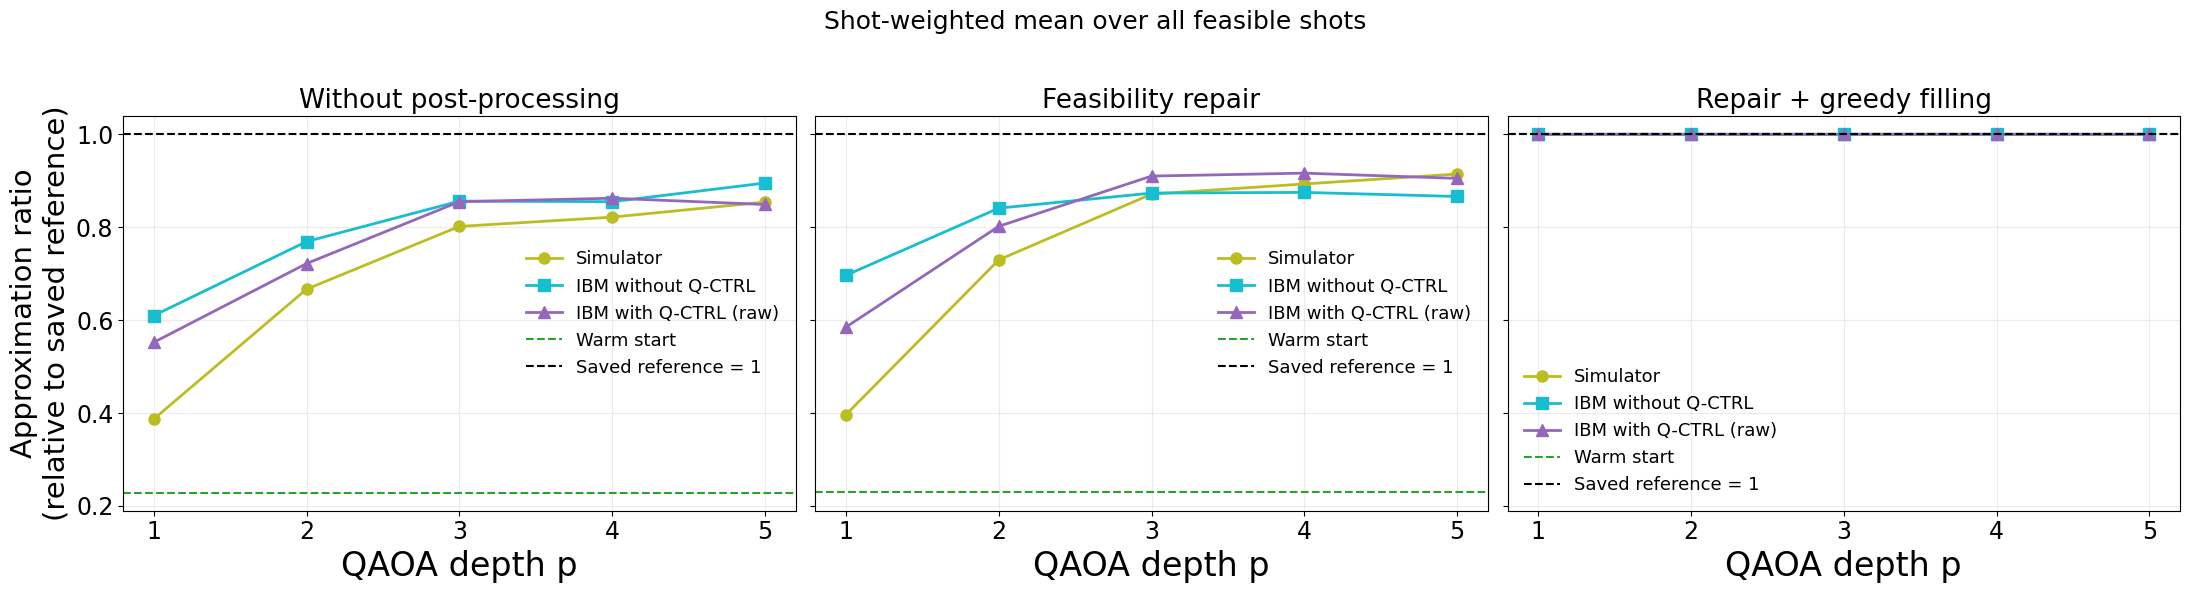

In [52]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt

# Select the repository containing the FINAL saved 100-item experiment.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "copula_qaoa").is_dir()
     and (p / "results" / "final_100_items" / "analysis" / "summary.json").is_file()),
    Path("/Users/naeimeh/Downloads/Copula_QAOA"),
)
sys.path.insert(0, str(PROJECT_ROOT))
from copula_qaoa.final_results import load_final_results, plot_final_results
RUN_DIR = PROJECT_ROOT / "results" / "final_100_items"
saved_results = load_final_results(RUN_DIR)

# Choose 8_000, 20_000, or None (all feasible shots).
AR_TOP_K = None
AR_METRICS = {8_000: "ar_top8000", 20_000: "ar_top20000", None: "ar_all_feasible"}
if AR_TOP_K not in AR_METRICS:
    raise ValueError("The saved summaries support AR_TOP_K = 8000, 20000 or None.")
metric = AR_METRICS[AR_TOP_K]
fig_ar, axes_ar = plot_final_results(RUN_DIR, metric=metric)
axes_ar[0].set_ylabel("Approximation ratio\n(relative to saved reference)", fontsize=21)
selection = "all feasible shots" if AR_TOP_K is None else f"best up to {AR_TOP_K:,} feasible shots"
fig_ar.suptitle(f"Shot-weighted mean over {selection}", fontsize=18)
fig_ar.tight_layout(rect=(0, 0, 1, 0.94))
print("Reference: saved Gurobi value", saved_results["reference"]["value"])
print("This reference is not proven optimal. No feasible samples are shown as gaps.")
print("If fewer than K feasible shots exist, all available feasible shots are used.")
plt.show()

# Actual shot counts used are saved, not assumed:
# saved_results["series"]["IBM with Q-CTRL (raw)"]["5"]["before"][metric + "_shots_used"]


In [ ]:
import json
from pathlib import Path

RUN_DIR = Path(
    "/Users/naeimeh/Downloads/Copula_QAOA/results/final_100_items"
)

# Change these:
METHOD = "Simulator"
# Other choices: "IBM without Q-CTRL", "IBM with Q-CTRL"
P = 5
STAGE = "completion"   # "before", "repair", or "completion"

summary = json.loads(
    (RUN_DIR / "analysis" / "summary.json").read_text()
)
distributions = json.loads(
    (RUN_DIR / "analysis" / "distributions.json").read_text()
)

reference = summary["reference"]["value"]
distribution = distributions["series"][METHOD][str(P)][STAGE]

feasible = {
    int(value): int(count)
    for value, count in distribution["feasible_by_value"].items()
}
infeasible_shots = sum(distribution["infeasible_by_value"].values())
feasible_shots = sum(feasible.values())
total_shots = feasible_shots + infeasible_shots

if not feasible_shots:
    raise ValueError("There are no feasible shots in this selection.")

# Each value is multiplied by its actual frequency.
weighted_sum = sum(value * count for value, count in feasible.items())
mean_value = weighted_sum / feasible_shots

print(f"{METHOD}, p={P}, stage={STAGE}")
print(f"Total shots:       {total_shots:,}")
print(f"Feasible shots:    {feasible_shots:,}")
print(f"Reference value:   {reference:,.0f}")
print(f"Mean feasible value: {mean_value:,.3f}")
print(f"Mean shortfall:      {reference - mean_value:,.3f}")
print()
print(f"Conditional ratio: {mean_value / reference:.12f}")
print(f"All-shot ratio:    {weighted_sum / (total_shots * reference):.12f}")

print("\nHow often do we reach the reference or get close?")
print("Percentages below use ALL shots as the denominator.\n")
print(f"{'Allowed shortfall':>20} {'Qualifying shots':>20} {'Percentage':>14}")

for allowed_shortfall in [0, 1_000, 100_000, 1_000_000]:
    threshold = reference - allowed_shortfall
    qualifying = sum(
        count for value, count in feasible.items()
        if value >= threshold
    )
    print(
        f"{allowed_shortfall:>20,}"
        f"{qualifying:>20,}"
        f"{100 * qualifying / total_shots:>13.3f}%"
    )

Simulator, p=5, stage=completion
Total shots:       100,000
Feasible shots:    100,000
Reference value:   9,689,707,983
Mean feasible value: 9,689,145,903.477
Mean shortfall:      562,079.523

Conditional ratio: 0.999941992109
All-shot ratio:    0.999941992109

How often do we reach the reference or get close?
Percentages below use ALL shots as the denominator.

   Allowed shortfall     Qualifying shots     Percentage
                   0                   0        0.000%
               1,000                  78        0.078%
             100,000                  78        0.078%
           1,000,000              96,867       96.867%


In [140]:
job = service.job("d8biq8r8ch0s738tiq60")

from qiskit.circuit import Gate



for i, pub in enumerate(job.inputs["pubs"]):
    circuit = pub.circuit if hasattr(pub, "circuit") else pub[0]

    # Exclude Q-CTRL readout-calibration circuits.
    if "readout_mitigation" in circuit.name:
        continue

    def is_two_qubit_gate(instruction):
        return (
            isinstance(instruction.operation, Gate)
            and instruction.operation.num_qubits == 2
        )

    two_q_depth = circuit.depth(filter_function=is_two_qubit_gate)
    two_q_count = sum(is_two_qubit_gate(inst) for inst in circuit.data)

    print(
        f"{circuit.name}: "
        f"2-qubit depth = {two_q_depth}, "
        f"2-qubit gate count = {two_q_count}"
    )

circuit-2112: 2-qubit depth = 27, 2-qubit gate count = 370
circuit-2112: 2-qubit depth = 81, 2-qubit gate count = 614
circuit-2112: 2-qubit depth = 60, 2-qubit gate count = 634
circuit-2112: 2-qubit depth = 92, 2-qubit gate count = 823


In [141]:
for i, pub in enumerate(job.inputs["pubs"]):
    circuit = pub.circuit if hasattr(pub, "circuit") else pub[0]

    if "readout_mitigation" in circuit.name:
        continue

    measured_qubits = {
        circuit.find_bit(qubit).index
        for instruction in circuit.data
        if instruction.operation.name == "measure"
        for qubit in instruction.qubits
    }

    print(
        f"Circuit {i}: "
        f"total qubits = {circuit.num_qubits}, "
        f"measured qubits = {len(measured_qubits)}"
    )

Circuit 0: total qubits = 156, measured qubits = 150
Circuit 1: total qubits = 156, measured qubits = 150
Circuit 2: total qubits = 156, measured qubits = 150
Circuit 3: total qubits = 156, measured qubits = 150
